# DT.ipynb — Detector từ đầu (PyTorch) cho Edge AI Challenge 2026 Lần 2

**Bài 70 điểm = detection, chấm mAP50 trên 7 lớp.** Model < 200k tham số, train *from scratch* (không pretrained), xuất TFLite INT8 (TFLM).

| Cell | Việc |
|---|---|
| 1 | Import + `CFG` (đổi epoch / batch / kích thước ảnh ở đây) |
| 2 | Chia dữ liệu K-fold stratified đa nhãn (4800 train / 1200 val) |
| 3a, 3b | Dataset, augment (mosaic, scale, HSV, flip), gán target, DataLoader |
| 4 | Model (tái tạo MicroEdgeCNN-UltraV2 + tối ưu), đếm tham số / MACs |
| 5 | Loss (QFL + CIoU), decode/NMS, mAP50, Trainer (checkpoint, EMA, best) |
| 6 | Chạy (`bench` đo tốc độ / `train`) |
| 7 | Kết quả: đường cong, AP từng lớp, lỗi theo loại / kích thước, ảnh minh họa |
| 8 | Dự đoán, xuất INT8 (Keras mirror), kiểm tra op, file nộp (chưa nộp gì) |

**Số khuyến nghị (RTX 4060 8GB):** ảnh `320x240` (native camera), `BATCH=32`, `EPOCHS=400` (đo thực tế trên RTX 4060: ~35 s/epoch → ~4.5 giờ), `FOLD=0`.
Có thể chạy `RUN_MODE="bench"` ở cell 6 để đo lại tốc độ rồi chỉnh `EPOCHS`. Checkpoint lưu mỗi epoch (`checkpoints/last.pt`), tự resume.

Thư mục: `checkpoints/` (last.pt, epoch_XXX.pt, log.csv) · `best/` (best.pt theo mAP50 của EMA) · `splits/` · `export/`.


In [2]:
# ============================================================================
# CELL 1 - IMPORT + CONFIG
# ----------------------------------------------------------------------------
# Edge AI Challenge 2026 (Lan 2) - Detection (70 diem = 70 x mAP50)
# From-scratch PyTorch detector (<200k params) -> export TFLite INT8 (TFLM ops)
#
# SO KHUYEN NGHI (RTX 4060 8GB, du lieu 6000 anh 320x240):
#   IMG_W x IMG_H = 320 x 240   (native camera -> KHONG resize, khong lech tien xu ly tren ESP32)
#   BATCH         = 32          (BN on dinh; 64 neu muon nhanh hon, LR tu scale theo batch)
#   EPOCHS        = 400         (RTX 4060 do thuc te: 35 s/epoch + eval ~24 s moi 5 epoch -> 400 epoch ~ 4.5 gio)
#   FOLD          = 0 of 5      (4800 train / 1200 val, stratified da nhan)
# Muon doi do phan giai: IMG_W, IMG_H phai chia het cho 16 (vd 256x192, 288x224).
# ============================================================================
import os, sys, json, math, time, copy, random, shutil, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F

cv2.setNumThreads(0)  # tranh tranh chap CPU voi DataLoader workers
warnings.filterwarnings("ignore", category=UserWarning)

# --------------------------------------------------------------------------- #
# Duong dan
# --------------------------------------------------------------------------- #
ROOT = Path(os.environ.get("DT_ROOT", Path.cwd())).resolve()      # thu muc DuyToan/ (noi chua notebook)
sys.path.insert(0, str(ROOT))                                      # de import dt_data.py (DataLoader workers)

def find_data_root():
    cands = []
    if os.environ.get("DT_DATA"):
        cands.append(Path(os.environ["DT_DATA"]))
    cands += [
        ROOT.parent / "data" / "kaggle_lan2",
        ROOT / "data" / "kaggle_lan2",
        Path("/kaggle/input/egde-ai-challenge-2026-lan-2-qualifiers"),
        Path("/kaggle/input/edge-ai-challenge-2026-lan-2-qualifiers"),
    ]
    for c in cands:
        if (c / "train" / "images").exists():
            return c
    raise FileNotFoundError("Khong tim thay data. Dat bien moi truong DT_DATA hoac sua find_data_root(). Da thu: "
                            + ", ".join(str(c) for c in cands))

DATA_ROOT = find_data_root()
DIR_CKPT   = ROOT / "checkpoints"   # last.pt (moi epoch) + epoch_XXX.pt (dinh ky)
DIR_BEST   = ROOT / "best"          # best.pt (theo mAP50 cua EMA) + best_meta.json
DIR_SPLIT  = ROOT / "splits"        # folds.csv, train_split.txt, val_split.txt
DIR_EXPORT = ROOT / "export"        # .tflite INT8, file submission
for d in (DIR_CKPT, DIR_BEST, DIR_SPLIT, DIR_EXPORT):
    d.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["bottle", "cup", "phone", "book", "mouse", "box", "toy_car"]  # ID co dinh theo de bai
NUM_CLASSES = 7
ORIG_W, ORIG_H = 320, 240       # kich thuoc anh goc (camera OV7670)


class CFG:
    # ------------------------- DAY LA PHAN BAN CHINH -------------------------
    IMG_W = 320                  # chia het cho 16, <= 320
    IMG_H = 240                  # chia het cho 16, <= 240
    BATCH = 128
    EPOCHS = 500                 # tong so epoch (da xong 400 -> tu resume chay tiep 401..500)
    # -------------------------------------------------------------------------

    # chia du lieu
    SEED = 42
    N_FOLDS = 5
    FOLD = 0                     # 0..4 ; 1200 anh val / 4800 anh train

    # kien truc
    HEAD_CH = 96                 # kenh nhanh cls/box (tang -> nhieu tham so)
    USE_P2 = True                # dua dac trung stride-4 vao fusion (giup vat nho: mouse/toy_car/phone)
    MAX_DIST = 20.0              # box ltrb toi da = 20 o (x stride = 160 px) ; sigmoid*MAX_DIST
    STRIDE = 8                   # luoi du doan stride 8 (40x30 voi 320x240)
    PARAM_LIMIT = 200_000        # gioi han de bai (dem NGHIEM: gom ca BN mean/var nhu Keras count_params)
    PARAM_TARGET = 195_000       # tu dat de du bien an toan

    # toi uu
    LR = 2e-3                    # cho batch 32; tu scale tuyen tinh theo batch (xem LR_EFF)
    WEIGHT_DECAY = 0.02
    WARMUP_EPOCHS = 3
    LR_FINAL_FRAC = 0.01         # cosine ve 1% LR
    # KEO DAI train (resume tu last.pt da xong EXTEND_FROM epoch): tu epoch EXTEND_FROM tro di dung cosine MOI,
    # bat dau o LR_EFF*EXTEND_PEAK_FRAC (nhe hon LR dau 20 lan) roi ve LR_EFF*LR_FINAL_FRAC o epoch cuoi.
    # Neu khong dat, doi EPOCHS 400->500 se lam LR nhay tu 8e-5 len ~8e-4. Train MOI tu dau: dat EXTEND_FROM = 0.
    EXTEND_FROM = 400
    EXTEND_PEAK_FRAC = 0.05
    GRAD_CLIP = 10.0
    EMA_DECAY = 0.9995
    AMP = True                   # fp16 autocast tren GPU (tu tat khi khong co CUDA)

    # loss
    W_CLS = 1.0
    W_BOX = 3.0
    QFL_BETA = 2.0
    QFL_RAMP_EPOCHS = 20         # 20 epoch dau: target cls chuyen dan tu 1.0 -> IoU
    # phat THEM False Positive (cong them vao QFL, cung chuan hoa theo so o duong):
    #   W_FP      : o NEN THAT (ngoai moi box, khong phai o "trong vat the") ma du doan co vat
    #   W_CONFUSE : kenh SAI LOP tai o duong (vd phone doan thanh book) -> phan lon FP o val nam o day (cls_err)
    # dat 0.0 de tat. Tang neu bg_fp / cls_err trong log.csv van cao, giam neu recall (missed) tang.
    W_FP = 0.5
    W_CONFUSE = 1.0

    # augment
    MOSAIC_P = 0.5
    CLOSE_MOSAIC = 15            # tat mosaic + xoay o N epoch cuoi (fine-tune tren anh sach, giong test)
    SCALE = (0.75, 1.25)
    TRANSLATE = 0.10
    FLIP_P = 0.5
    ROTATE = 20.0                # xoay ngau nhien +-20 do (0 = tat)
    ROTATE_P = 0.5               # xac suat 1 anh bi xoay
    ROT_TIGHT = 0.5              # 0 = box bao 4 goc (phong to khi xoay) ; 1 = uoc luong elip (chat hon) ; 0.5 = tron
    # HSV: test co mau bao hoa (sat ~60) va doi tuong khac mau so voi train (sat ~43; coc xanh, sach xanh, chuot do...)
    # -> tang hue 0.015->0.04 va sat 0.5->0.7 de mo hinh bam vao HINH DANG thay vi mau.
    HSV = (0.04, 0.7, 0.35)
    PHOTO_P = 0.5                # lech mau RGB / mo nhe / nhieu (xem _photo_extra), 0 = tat

    # dataloader
    NUM_WORKERS = max(0, min(4, (os.cpu_count() or 4) - 2))   # 4 workers (~1000 mau/s) du cho GPU; moi worker ~400MB RAM
    TRAIN_LIMIT = None           # None = toan bo (dung cho dry-run)
    VAL_LIMIT = None
    TEST_LIMIT = None

    # danh gia / luu
    EVAL_EVERY = 5               # moi N epoch tinh mAP50 (EMA); N epoch cuoi tinh moi epoch
    SAVE_EVERY = 5               # luu epoch_XXX.pt moi N epoch (last.pt luu MOI epoch)
    RESUME = True                # tiep tuc tu checkpoints/last.pt neu co
    RUN_TAG = "v2_rot20_fp"      # nhan lan train. last.pt cua lan train KHAC tag (vd ban 400 epoch cu) bi bo qua -> train moi tu dau

    # decode (ngoai graph, giong luc chay tren ESP32 bang C)
    SCORE_THR = 0.001            # dung cho mAP; chon nguong deploy rieng sau
    NMS_IOU = 0.60
    PRE_NMS = 1000
    MAX_DET = 100

    # xuat INT8
    EXPORT_INT8 = True
    CALIB_IMAGES = 200
    INTENT_PRED_CSV = None       # vd "path/intent_preds.csv" (cot sample_id,prediction) de ghep vao file nop

    # ---- dry-run (kiem tra code, KHONG train that): dat DT_DRYRUN=1 ----
    if os.environ.get("DT_DRYRUN") == "1":
        EPOCHS = int(os.environ.get("DT_EPOCHS", 2))
        BATCH = 8
        IMG_W = int(os.environ.get("DT_W", IMG_W))
        IMG_H = int(os.environ.get("DT_H", IMG_H))
        TRAIN_LIMIT, VAL_LIMIT, TEST_LIMIT = 48, 24, 16
        NUM_WORKERS = int(os.environ.get("DT_WORKERS", 2))
        EVAL_EVERY = 1
        SAVE_EVERY = 1
        WARMUP_EPOCHS = 1
        QFL_RAMP_EPOCHS = 1
        CLOSE_MOSAIC = 1
        CALIB_IMAGES = 12
        RESUME = os.environ.get("DT_RESUME") == "1"
        EXTEND_FROM = int(os.environ.get("DT_EXTEND_FROM", 0))


CFG.LR_EFF = CFG.LR * CFG.BATCH / 32.0
assert CFG.IMG_W % 16 == 0 and CFG.IMG_H % 16 == 0, "IMG_W/IMG_H phai chia het cho 16"
assert CFG.IMG_W <= 320 and CFG.IMG_H <= 240, "De bai: input <= 320x240"
CFG.GRID_W, CFG.GRID_H = CFG.IMG_W // CFG.STRIDE, CFG.IMG_H // CFG.STRIDE


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CFG.SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True        # input co dinh -> nhanh hon
else:
    CFG.AMP = False
    print("!!! CANH BAO: khong thay CUDA -> dang chay CPU (rat cham). Neu co RTX 4060, cai torch ban CUDA:")
    print("    pip install torch --index-url https://download.pytorch.org/whl/cu128")

print(f"python {platform.python_version()} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)}, {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB)" if DEVICE.type == "cuda" else ""))
print(f"DATA_ROOT = {DATA_ROOT}")
print(f"ROOT      = {ROOT}")
print(f"input {CFG.IMG_W}x{CFG.IMG_H} | grid {CFG.GRID_W}x{CFG.GRID_H} (stride {CFG.STRIDE}) | batch {CFG.BATCH} | "
      f"epochs {CFG.EPOCHS} | lr {CFG.LR_EFF:.2e} | workers {CFG.NUM_WORKERS} | AMP {CFG.AMP}")


python 3.12.3 | torch 2.9.1+cu128 | device cuda (NVIDIA GeForce RTX 4060 Laptop GPU, 8.0 GB)
DATA_ROOT = E:\Python\EdgeAI-2026\data\kaggle_lan2
ROOT      = E:\Python\EdgeAI-2026\DuyToan
input 320x240 | grid 40x30 (stride 8) | batch 128 | epochs 500 | lr 8.00e-03 | workers 4 | AMP True


In [3]:
# ============================================================================
# CELL 2 - CHIA DU LIEU (K-fold STRATIFIED da nhan, khong dung anh test)
# ----------------------------------------------------------------------------
# - Moi anh co nhieu vat the -> dung "iterative stratification" (Sechidis 2011):
#   nhan = [lop c co mat] x7 + [lop c xuat hien >=2 lan] x7  => val giu dung ti le lop + mat do.
# - Ghi folds.csv, train_split.txt, val_split.txt (de tai tao ket qua).
# ============================================================================
TRAIN_IMG_DIR = DATA_ROOT / "train" / "images"
TRAIN_LBL_DIR = DATA_ROOT / "train" / "labels"
TEST_IMG_DIR = DATA_ROOT / "test" / "images"


def read_label_file(path):
    """YOLO txt (cls cx cy w h, chuan hoa) -> mang (N,5): cls, x1, y1, x2, y2 theo PIXEL 320x240."""
    rows = []
    if path.exists():
        for line in path.read_text().splitlines():
            p = line.split()
            if len(p) >= 5:
                c, cx, cy, w, h = int(p[0]), *map(float, p[1:5])
                rows.append([c, (cx - w / 2) * ORIG_W, (cy - h / 2) * ORIG_H, (cx + w / 2) * ORIG_W, (cy + h / 2) * ORIG_H])
    return np.asarray(rows, dtype=np.float32).reshape(-1, 5)


def iterative_stratification(Y, k, seed):
    """Y: (n, L) 0/1. Tra ve fold (n,) trong [0,k). Can bang tung nhan giua cac fold."""
    rng = np.random.RandomState(seed)
    n, L = Y.shape
    folds = -np.ones(n, dtype=int)
    remaining = np.ones(n, dtype=bool)
    c_fold = np.full(k, n / k)                                   # so mau mong muon / fold
    c_fold_label = np.outer(np.full(k, 1.0 / k), Y.sum(0))       # (k, L) so mau mong muon / fold / nhan
    while remaining.any():
        rem_counts = Y[remaining].sum(0)
        cand = np.where(rem_counts > 0)[0]
        if len(cand) == 0:
            break
        l = cand[np.argmin(rem_counts[cand])]                    # nhan hiem nhat truoc
        idx = np.where(remaining & (Y[:, l] == 1))[0]
        rng.shuffle(idx)
        for i in idx:
            m = c_fold_label[:, l].max()
            ks = np.where(c_fold_label[:, l] == m)[0]
            if len(ks) > 1:
                ks = ks[c_fold[ks] == c_fold[ks].max()]
            f = int(rng.choice(ks))
            folds[i] = f
            remaining[i] = False
            c_fold[f] -= 1
            c_fold_label[f] -= Y[i]
    for i in np.where(remaining)[0]:                             # anh khong co nhan nao (khong xay ra o day)
        f = int(np.argmax(c_fold))
        folds[i] = f
        c_fold[f] -= 1
    return folds


ALL_IDS = sorted(p.stem for p in TRAIN_IMG_DIR.glob("*.png"))
ALL_LABELS = {i: read_label_file(TRAIN_LBL_DIR / f"{i}.txt") for i in ALL_IDS}
TEST_IDS = sorted(p.stem for p in TEST_IMG_DIR.glob("*.png"))
assert len(ALL_IDS) > 0, f"Khong co anh train trong {TRAIN_IMG_DIR}"

Y = np.zeros((len(ALL_IDS), 2 * NUM_CLASSES), dtype=np.int64)
for r, i in enumerate(ALL_IDS):
    cls = ALL_LABELS[i][:, 0].astype(int)
    for c in range(NUM_CLASSES):
        n_c = int((cls == c).sum())
        Y[r, c] = int(n_c >= 1)
        Y[r, NUM_CLASSES + c] = int(n_c >= 2)

folds = iterative_stratification(Y, CFG.N_FOLDS, CFG.SEED)
pd.DataFrame({"id": ALL_IDS, "fold": folds}).to_csv(DIR_SPLIT / "folds.csv", index=False)

TRAIN_IDS = [i for i, f in zip(ALL_IDS, folds) if f != CFG.FOLD]
VAL_IDS = [i for i, f in zip(ALL_IDS, folds) if f == CFG.FOLD]
(DIR_SPLIT / "train_split.txt").write_text("\n".join(TRAIN_IDS))
(DIR_SPLIT / "val_split.txt").write_text("\n".join(VAL_IDS))

# --- bao cao can bang ---
def box_counts(ids):
    cnt = np.zeros(NUM_CLASSES, dtype=int)
    for i in ids:
        for c in ALL_LABELS[i][:, 0].astype(int):
            cnt[c] += 1
    return cnt

rep = pd.DataFrame({"train_boxes": box_counts(TRAIN_IDS), "val_boxes": box_counts(VAL_IDS)}, index=CLASS_NAMES)
rep["val_share_%"] = (100 * rep.val_boxes / (rep.train_boxes + rep.val_boxes)).round(2)
print(f"[split] fold {CFG.FOLD}/{CFG.N_FOLDS}: train {len(TRAIN_IDS)} anh | val {len(VAL_IDS)} anh | test {len(TEST_IDS)} anh")
print(f"[split] ky vong val share = {100 / CFG.N_FOLDS:.1f}% moi lop")
print(rep.to_string())
fold_sizes = np.bincount(folds, minlength=CFG.N_FOLDS)
print("[split] so anh moi fold:", fold_sizes.tolist(), "| lech lop toi da so voi ky vong:",
      f"{np.abs(rep['val_share_%'] - 100 / CFG.N_FOLDS).max():.2f} diem %")

# --- bao cao can bang theo KICH THUOC vat the (sqrt(w*h) px) giua cac fold: val co du vat nho/vua/lon khong ---
SIZE_BINS = [(0, 16), (16, 24), (24, 32), (32, 48), (48, 1e9)]
SIZE_LABELS = ["<16", "16-24", "24-32", "32-48", ">=48"]


def size_hist(ids):
    s = np.array([math.sqrt(max(0.0, (g[3] - g[1]) * (g[4] - g[2]))) for i in ids for g in ALL_LABELS[i]])
    return np.array([int(((s >= lo) & (s < hi)).sum()) for lo, hi in SIZE_BINS]), s


h_tr, _ = size_hist(TRAIN_IDS)
h_va, s_va = size_hist(VAL_IDS)
rep2 = pd.DataFrame({"train": h_tr, "val": h_va, "val_share_%": (100 * h_va / np.maximum(h_tr + h_va, 1)).round(2)}, index=SIZE_LABELS)
print("[split] kich thuoc vat (px):")
print(rep2.to_string())
# vat nho theo tung lop (mouse/toy_car/phone la lop kho nhat): val phai nhan du phan cua minh
small_rows = []
for c in range(NUM_CLASSES):
    tr_n = sum(int(((ALL_LABELS[i][:, 0] == c) & (np.sqrt((ALL_LABELS[i][:, 3] - ALL_LABELS[i][:, 1]) * (ALL_LABELS[i][:, 4] - ALL_LABELS[i][:, 2])) < 24)).sum()) for i in TRAIN_IDS)
    va_n = sum(int(((ALL_LABELS[i][:, 0] == c) & (np.sqrt((ALL_LABELS[i][:, 3] - ALL_LABELS[i][:, 1]) * (ALL_LABELS[i][:, 4] - ALL_LABELS[i][:, 2])) < 24)).sum()) for i in VAL_IDS)
    small_rows.append(dict(cls=CLASS_NAMES[c], small_train=tr_n, small_val=va_n, val_share_pct=round(100 * va_n / max(tr_n + va_n, 1), 2)))
print("[split] vat NHO (<24px) theo lop:")
print(pd.DataFrame(small_rows).set_index("cls").to_string())
_dev = np.abs(rep2["val_share_%"].values - 100 / CFG.N_FOLDS).max()
print(f"[split] lech kich thuoc toi da so voi ky vong: {_dev:.2f} diem % ({'OK' if _dev < 2.0 else 'LECH - xem lai SEED / doi fold'})")

# gioi han so luong (chi dung cho dry-run)
if CFG.TRAIN_LIMIT:
    TRAIN_IDS = TRAIN_IDS[: CFG.TRAIN_LIMIT]
if CFG.VAL_LIMIT:
    VAL_IDS = VAL_IDS[: CFG.VAL_LIMIT]
if CFG.TEST_LIMIT:
    TEST_IDS = TEST_IDS[: CFG.TEST_LIMIT]

VAL_GT = [ALL_LABELS[i] for i in VAL_IDS]   # ground truth theo pixel 320x240 de tinh mAP


[split] fold 0/5: train 4804 anh | val 1196 anh | test 4000 anh
[split] ky vong val share = 20.0% moi lop
         train_boxes  val_boxes  val_share_%
bottle          4652       1146        19.77
cup             4559       1148        20.12
phone           4584       1144        19.97
book            4131       1068        20.54
mouse           4409       1101        19.98
box             4090       1031        20.13
toy_car         4570       1141        19.98
[split] so anh moi fold: [1196, 1189, 1211, 1185, 1219] | lech lop toi da so voi ky vong: 0.54 diem %
[split] kich thuoc vat (px):
       train   val  val_share_%
<16     1116   301        21.24
16-24   4571  1138        19.93
24-32   6821  1709        20.04
32-48  10812  2660        19.74
>=48    7675  1971        20.43
[split] vat NHO (<24px) theo lop:
         small_train  small_val  val_share_pct
cls                                           
bottle           180         45          20.00
cup              372         82     

In [4]:
%%writefile dt_data.py
# ============================================================================
# dt_data.py  -  Dataset + augmentation + gan target (CELL 3a ghi file nay)
# Viet thanh module rieng de DataLoader(num_workers>0) chay duoc tren Windows (spawn).
# ============================================================================
import math
import multiprocessing as mp
from pathlib import Path

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset

cv2.setNumThreads(0)


def assign_targets(boxes, gw, gh, stride, min_r=1.5, max_r=3.0, rad_scale=0.3):
    """Gan target tren luoi (gh, gw) cho cac box (N,5)=[cls,x1,y1,x2,y2] (pixel, he toa do input).
    - Moi vat the: o chua tam + cac o co TAM nam trong box va gan tam (center sampling ~3x3, vat to toi da 7x7).
    - o bi nhieu vat tranh nhau -> uu tien vat NHO HON (bao ve vat nho).
    Tra ve cls_idx (gh,gw) int64 (>=0 duong, -1 = nen that, -2 = trong vat the nhung khong duong) va box_t (4,gh,gw) float32 xyxy pixel.
    """
    cls_idx = np.full((gh, gw), -1, dtype=np.int64)
    box_t = np.zeros((4, gh, gw), dtype=np.float32)
    best_area = np.full((gh, gw), np.inf, dtype=np.float32)
    for c, x1, y1, x2, y2 in boxes:
        w, h = x2 - x1, y2 - y1
        if w <= 1 or h <= 1:
            continue
        cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
        ci = min(max(int(cx // stride), 0), gw - 1)
        cj = min(max(int(cy // stride), 0), gh - 1)
        r = float(np.clip(rad_scale * min(w, h) / stride, min_r, max_r))
        reach = int(math.ceil(r))
        area = w * h
        for j in range(max(0, cj - reach), min(gh, cj + reach + 1)):
            ccy = (j + 0.5) * stride
            for i in range(max(0, ci - reach), min(gw, ci + reach + 1)):
                ccx = (i + 0.5) * stride
                is_center = (i == ci and j == cj)
                inside = (x1 <= ccx <= x2) and (y1 <= ccy <= y2)
                near = abs(ccx - cx) <= r * stride and abs(ccy - cy) <= r * stride
                if is_center or (inside and near):
                    if area < best_area[j, i]:
                        best_area[j, i] = area
                        cls_idx[j, i] = int(c)
                        box_t[:, j, i] = (x1, y1, x2, y2)
    # o co TAM nam trong box nhung khong phai o duong -> -2 ("trong vat the"): loss FP khong phat o nay
    inside = np.zeros((gh, gw), dtype=bool)
    for c, x1, y1, x2, y2 in boxes:
        if x2 - x1 <= 1 or y2 - y1 <= 1:
            continue
        i0, i1 = max(0, int(math.ceil(x1 / stride - 0.5))), min(gw - 1, int(math.floor(x2 / stride - 0.5)))
        j0, j1 = max(0, int(math.ceil(y1 / stride - 0.5))), min(gh - 1, int(math.floor(y2 / stride - 0.5)))
        if i1 >= i0 and j1 >= j0:
            inside[j0:j1 + 1, i0:i1 + 1] = True
    cls_idx[(cls_idx == -1) & inside] = -2
    return cls_idx, box_t


def _make_affine(rng, W, H, s, src_c, jitter, rot_deg, rot_p):
    """Ma tran 2x3: scale s + xoay (+-rot_deg, xac suat rot_p) quanh tam nguon src_c, roi dua tam ve giua anh (+jitter)."""
    ang = rng.uniform(-rot_deg, rot_deg) if (rot_deg > 0 and rng.random() < rot_p) else 0.0
    a = math.radians(ang)
    R = s * np.array([[math.cos(a), -math.sin(a)], [math.sin(a), math.cos(a)]], dtype=np.float64)
    dst = np.array([W / 2 + jitter[0], H / 2 + jitter[1]])
    M = np.zeros((2, 3), dtype=np.float64)
    M[:, :2] = R
    M[:, 2] = dst - R @ np.asarray(src_c, dtype=np.float64)
    return M.astype(np.float32), a


def _affine_boxes(boxes, M, ang, W, H, min_vis=0.4, min_size=2.0, rot_tight=0.5):
    """Bien doi box theo M (scale/xoay/tinh tien). Khi xoay, box bao 4 goc bi PHONG TO (toi ~1.3x o 20 do)
    -> tron `rot_tight` voi uoc luong 'vat hinh elip' (bottle/cup/mouse/toy_car tron hon hop bao) de box it bi phong."""
    if len(boxes) == 0:
        return boxes
    b = boxes.copy()
    s = float(np.sqrt(abs(np.linalg.det(M[:, :2]))))
    w0, h0 = (b[:, 3] - b[:, 1]), (b[:, 4] - b[:, 2])
    c0 = np.stack([(b[:, 1] + b[:, 3]) / 2, (b[:, 2] + b[:, 4]) / 2], 1)
    c1 = c0 @ M[:, :2].T + M[:, 2]
    ca, sa = abs(math.cos(ang)), abs(math.sin(ang))
    hw_rect = s * (w0 * ca + h0 * sa) / 2
    hh_rect = s * (w0 * sa + h0 * ca) / 2
    hw_ell = s * np.sqrt((w0 * ca / 2) ** 2 + (h0 * sa / 2) ** 2)
    hh_ell = s * np.sqrt((w0 * sa / 2) ** 2 + (h0 * ca / 2) ** 2)
    hw = (1 - rot_tight) * hw_rect + rot_tight * hw_ell
    hh = (1 - rot_tight) * hh_rect + rot_tight * hh_ell
    b[:, 1], b[:, 3] = c1[:, 0] - hw, c1[:, 0] + hw
    b[:, 2], b[:, 4] = c1[:, 1] - hh, c1[:, 1] + hh
    area0 = (b[:, 3] - b[:, 1]) * (b[:, 4] - b[:, 2])
    b[:, [1, 3]] = b[:, [1, 3]].clip(0, W)
    b[:, [2, 4]] = b[:, [2, 4]].clip(0, H)
    w, h = b[:, 3] - b[:, 1], b[:, 4] - b[:, 2]
    keep = (w >= min_size) & (h >= min_size) & (w * h >= min_vis * area0)   # bo box bi cat qua nhieu
    return b[keep]


def _hsv_jitter(img, rng, gains):
    r = rng.uniform(-1, 1, 3) * np.asarray(gains) + 1.0
    hue, sat, val = cv2.split(cv2.cvtColor(img, cv2.COLOR_RGB2HSV))
    x = np.arange(256, dtype=np.float32)
    lut_h = ((x * r[0]) % 180).astype(np.uint8)
    lut_s = np.clip(x * r[1], 0, 255).astype(np.uint8)
    lut_v = np.clip(x * r[2], 0, 255).astype(np.uint8)
    out = cv2.merge((cv2.LUT(hue, lut_h), cv2.LUT(sat, lut_s), cv2.LUT(val, lut_v)))
    return cv2.cvtColor(out, cv2.COLOR_HSV2RGB)


def _photo_extra(img, rng, p):
    """Lech mau kenh RGB + mo nhe + nhieu: test co vat/mau/do net khac train -> khong de mo hinh dua vao mau/do net."""
    if rng.random() >= p:
        return img
    out = img.astype(np.float32) * rng.uniform(0.9, 1.1, 3).astype(np.float32)
    if rng.random() < 0.3:
        k = int(rng.choice([3, 5]))
        out = cv2.GaussianBlur(out, (k, k), 0)
    if rng.random() < 0.3:
        out += rng.normal(0.0, rng.uniform(1.0, 6.0), out.shape).astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)


class DetDataset(Dataset):
    """Tra ve (img uint8 [3,H,W], cls_idx [gh,gw], box_t [4,gh,gw], idx).
    train=True: mosaic + scale/translate/XOAY + HSV + lat ngang. train=False: chi resize (neu can)."""

    def __init__(self, img_dir, ids, labels, img_w, img_h, stride, train,
                 mosaic_p=0.5, scale=(0.75, 1.25), translate=0.1, flip_p=0.5,
                 hsv=(0.015, 0.5, 0.35), orig_w=320, orig_h=240, seed=0, rotate=0.0, rotate_p=0.5, rot_tight=0.5, photo_p=0.0):
        self.img_dir = Path(img_dir)
        self.ids, self.labels = list(ids), list(labels)
        self.W, self.H, self.stride = int(img_w), int(img_h), int(stride)
        self.gw, self.gh = self.W // self.stride, self.H // self.stride
        self.train = train
        self.scale, self.translate, self.flip_p, self.hsv = scale, translate, flip_p, hsv
        self.rotate, self.rot_tight, self.photo_p = float(rotate), float(rot_tight), float(photo_p)
        self.rotate_p = mp.Value("d", float(rotate_p))      # dung chung workers: tat xoay o cac epoch cuoi
        self.orig_w, self.orig_h, self.seed = orig_w, orig_h, seed
        self.epoch = mp.Value("i", 0)             # dung chung voi workers (persistent_workers)
        self.mosaic_p = mp.Value("d", float(mosaic_p))

    def set_epoch(self, e):
        self.epoch.value = int(e)

    def set_mosaic(self, p):
        self.mosaic_p.value = float(p)

    def set_rotate(self, p):
        self.rotate_p.value = float(p)

    def __len__(self):
        return len(self.ids)

    # -------------------------------------------------------------------- #
    def _load(self, k):
        img = cv2.imread(str(self.img_dir / f"{self.ids[k]}.png"), cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(self.img_dir / f"{self.ids[k]}.png")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if img.shape[1] != self.W or img.shape[0] != self.H:
            img = cv2.resize(img, (self.W, self.H), interpolation=cv2.INTER_AREA)
        b = self.labels[k].copy()
        b[:, [1, 3]] *= self.W / self.orig_w
        b[:, [2, 4]] *= self.H / self.orig_h
        return img, b

    def _single(self, k, rng):
        W, H = self.W, self.H
        img, b = self._load(k)
        s = rng.uniform(*self.scale)
        jit = (rng.uniform(-self.translate, self.translate) * W, rng.uniform(-self.translate, self.translate) * H)
        M, ang = _make_affine(rng, W, H, s, (W / 2, H / 2), jit, self.rotate, self.rotate_p.value)
        img = cv2.warpAffine(img, M, (W, H), flags=cv2.INTER_LINEAR, borderValue=(114, 114, 114))
        return img, _affine_boxes(b, M, ang, W, H, rot_tight=self.rot_tight)

    def _mosaic(self, k, rng):
        W, H = self.W, self.H
        ids = [k] + [int(x) for x in rng.integers(0, len(self.ids), 3)]
        xc = int(rng.uniform(0.5 * W, 1.5 * W))
        yc = int(rng.uniform(0.5 * H, 1.5 * H))
        canvas = np.full((2 * H, 2 * W, 3), 114, dtype=np.uint8)
        all_b = []
        for n, i in enumerate(ids):
            img, b = self._load(i)
            if n == 0:
                x1a, y1a, x2a, y2a = max(xc - W, 0), max(yc - H, 0), xc, yc
                x1b, y1b, x2b, y2b = W - (x2a - x1a), H - (y2a - y1a), W, H
            elif n == 1:
                x1a, y1a, x2a, y2a = xc, max(yc - H, 0), min(xc + W, 2 * W), yc
                x1b, y1b, x2b, y2b = 0, H - (y2a - y1a), min(W, x2a - x1a), H
            elif n == 2:
                x1a, y1a, x2a, y2a = max(xc - W, 0), yc, xc, min(2 * H, yc + H)
                x1b, y1b, x2b, y2b = W - (x2a - x1a), 0, W, min(y2a - y1a, H)
            else:
                x1a, y1a, x2a, y2a = xc, yc, min(xc + W, 2 * W), min(2 * H, yc + H)
                x1b, y1b, x2b, y2b = 0, 0, min(W, x2a - x1a), min(y2a - y1a, H)
            canvas[y1a:y2a, x1a:x2a] = img[y1b:y2b, x1b:x2b]
            padw, padh = x1a - x1b, y1a - y1b
            if len(b):
                b = b.copy()
                b[:, [1, 3]] += padw
                b[:, [2, 4]] += padh
                # cat theo vung anh duoc dan vao canvas; bo box con thay < 40% dien tich goc
                area0 = (b[:, 3] - b[:, 1]) * (b[:, 4] - b[:, 2])
                b[:, [1, 3]] = b[:, [1, 3]].clip(x1a, x2a)
                b[:, [2, 4]] = b[:, [2, 4]].clip(y1a, y2a)
                bw, bh = b[:, 3] - b[:, 1], b[:, 4] - b[:, 2]
                ok = (bw >= 2) & (bh >= 2) & (bw * bh >= 0.4 * area0)
                all_b.append(b[ok])
        b = np.concatenate(all_b, 0) if all_b else np.zeros((0, 5), np.float32)
        s = rng.uniform(*self.scale)
        jit = (rng.uniform(-self.translate, self.translate) * W, rng.uniform(-self.translate, self.translate) * H)
        M, ang = _make_affine(rng, W, H, s, (W, H), jit, self.rotate, self.rotate_p.value)
        img = cv2.warpAffine(canvas, M, (W, H), flags=cv2.INTER_LINEAR, borderValue=(114, 114, 114))
        return img, _affine_boxes(b, M, ang, W, H, rot_tight=self.rot_tight)

    # -------------------------------------------------------------------- #
    def __getitem__(self, k):
        if self.train:
            rng = np.random.default_rng((self.seed * 1000003 + self.epoch.value * 100003 + k) & 0xFFFFFFFF)
            if rng.random() < self.mosaic_p.value:
                img, b = self._mosaic(k, rng)
            else:
                img, b = self._single(k, rng)
            img = _hsv_jitter(img, rng, self.hsv)
            img = _photo_extra(img, rng, self.photo_p)
            if rng.random() < self.flip_p:
                img = img[:, ::-1]
                if len(b):
                    b = b.copy()
                    x1, x2 = b[:, 1].copy(), b[:, 3].copy()
                    b[:, 1], b[:, 3] = self.W - x2, self.W - x1
        else:
            img, b = self._load(k)
        cls_idx, box_t = assign_targets(b, self.gw, self.gh, self.stride)
        img = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1)))
        return img, torch.from_numpy(cls_idx), torch.from_numpy(box_t), k


class ImageOnlyDataset(Dataset):
    """Cho du doan (test/calibration): tra ve (img uint8 [3,H,W], idx)."""

    def __init__(self, img_dir, ids, img_w, img_h):
        self.img_dir, self.ids, self.W, self.H = Path(img_dir), list(ids), int(img_w), int(img_h)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, k):
        img = cv2.imread(str(self.img_dir / f"{self.ids[k]}.png"), cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if img.shape[1] != self.W or img.shape[0] != self.H:
            img = cv2.resize(img, (self.W, self.H), interpolation=cv2.INTER_AREA)
        return torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))), k


Overwriting dt_data.py


In [5]:
# ============================================================================
# CELL 3b - TAO DATASET + DATALOADER
# ============================================================================
import importlib
import dt_data
importlib.reload(dt_data)
from dt_data import DetDataset, ImageOnlyDataset
from torch.utils.data import DataLoader


def make_loader(ds, batch, shuffle, workers, drop_last=False):
    kw = dict(batch_size=batch, shuffle=shuffle, num_workers=workers, drop_last=drop_last,
              pin_memory=(DEVICE.type == "cuda"))
    if workers > 0:
        kw.update(persistent_workers=True, prefetch_factor=4)
    return DataLoader(ds, **kw)


train_ds = DetDataset(TRAIN_IMG_DIR, TRAIN_IDS, [ALL_LABELS[i] for i in TRAIN_IDS], CFG.IMG_W, CFG.IMG_H, CFG.STRIDE,
                      train=True, mosaic_p=CFG.MOSAIC_P, scale=CFG.SCALE, translate=CFG.TRANSLATE,
                      flip_p=CFG.FLIP_P, hsv=CFG.HSV, orig_w=ORIG_W, orig_h=ORIG_H, seed=CFG.SEED,
                      rotate=CFG.ROTATE, rotate_p=CFG.ROTATE_P, rot_tight=CFG.ROT_TIGHT, photo_p=CFG.PHOTO_P)
val_ds = DetDataset(TRAIN_IMG_DIR, VAL_IDS, [ALL_LABELS[i] for i in VAL_IDS], CFG.IMG_W, CFG.IMG_H, CFG.STRIDE,
                    train=False, orig_w=ORIG_W, orig_h=ORIG_H, seed=CFG.SEED)

train_loader = make_loader(train_ds, CFG.BATCH, True, CFG.NUM_WORKERS, drop_last=True)
val_loader = make_loader(val_ds, max(CFG.BATCH, 32), False, min(CFG.NUM_WORKERS, 2))

print(f"[data] train {len(train_ds)} anh ({len(train_loader)} step/epoch) | val {len(val_ds)} anh | "
      f"grid {train_ds.gw}x{train_ds.gh}")

# --- kiem tra nhanh 1 mau: so o duong tinh tren moi anh ---
_img, _cls, _box, _ = train_ds[0]
_pos = int((_cls >= 0).sum())
_gt = int(len(ALL_LABELS[TRAIN_IDS[0]]))
print(f"[data] mau 0: img {tuple(_img.shape)} {_img.dtype} | o duong {_pos} | box goc {_gt} (mosaic/aug co the doi so box)")


[data] train 4804 anh (37 step/epoch) | val 1196 anh | grid 40x30
[data] mau 0: img (3, 240, 320) torch.uint8 | o duong 74 | box goc 5 (mosaic/aug co the doi so box)


In [6]:
# ============================================================================
# CELL 4 - MODEL  (tai tao MicroEdgeCNN-UltraV2 cua ban + toi uu)
# ----------------------------------------------------------------------------
# Giu nguyen: stem -> DW/PW + BN + ReLU6 + residual -> FPN-lite (nearest x2 + concat) -> head tach cls/box co DW3x3.
# Thay doi so voi ban goc:
#   * Bo khoi SE (dung phep Mul, khong co trong danh sach op TFLM cua de) -> thay bang them khoi residual.
#   * Them nhanh P2 (stride-4) vao fusion cho vat nho.
#   * Bo head `conf` rieng: dung 7 kenh cls (sigmoid, loss Quality-Focal) -> score = IoU-aware.
#   * Box = ltrb (khoang cach tu tam o toi 4 canh), decode NGOAI graph; output xuat dang logits (khong sigmoid)
#     -> INT8 giu duoc dai dong cua score.
#   * Padding stride-2 theo kieu TFLite 'SAME' (lech duoi/phai) de khop 100% khi chuyen sang TFLite.
# Kien truc duoc mo ta bang MOT danh sach `spec`; ca PyTorch (o day) va Keras (cell 8, de xuat INT8)
# deu dung chinh danh sach nay -> hai ben luon khop.
# ============================================================================
def make_spec(num_classes=NUM_CLASSES, head_ch=CFG.HEAD_CH, use_p2=CFG.USE_P2):
    ops = []

    def conv(name, src, cin, cout, k=1, s=1, bn=True, act=True, bias=False, zero_gamma=False):
        ops.append(dict(t="conv", name=name, src=src, cin=cin, cout=cout, k=k, s=s, bn=bn, act=act, bias=bias,
                        zero_gamma=zero_gamma))
        return name

    def dw(name, src, c, k=3, s=1, bn=True, act=True):
        ops.append(dict(t="dw", name=name, src=src, cin=c, cout=c, k=k, s=s, bn=bn, act=act, bias=False,
                        zero_gamma=False))
        return name

    def add(name, a, b):
        ops.append(dict(t="add", name=name, srcs=[a, b]))
        return name

    def cat(name, srcs):
        ops.append(dict(t="cat", name=name, srcs=list(srcs)))
        return name

    def up(name, src):
        ops.append(dict(t="up", name=name, src=src))
        return name

    def res(prefix, x, c):          # DW3x3+BN+ReLU6 -> PW+BN (tuyen tinh) -> cong tat
        a = dw(prefix + "_dw", x, c)
        b = conv(prefix + "_pw", a, c, c, act=False, zero_gamma=True)
        return add(prefix + "_add", x, b)

    x = conv("stem", "input", 3, 32, k=3, s=2)                       # /2
    x = dw("s1_dw", x, 32)
    x = conv("s1_pw", x, 32, 48, act=False)
    x = dw("s1_down_dw", x, 48, s=2)                                 # /4
    x = conv("s1_down_pw", x, 48, 64)
    p2 = res("s2a", x, 64)                                           # dac trung stride-4 (canh/chi tiet nho)
    x = dw("s2_down_dw", p2, 64, s=2)                                # /8
    x = conv("s2_down_pw", x, 64, 112)
    x = res("s2b", x, 112)
    shape = res("s2c", x, 112)                                       # dac trung hinh dang stride-8
    x = dw("s3_down_dw", shape, 112, s=2)                            # /16
    x = conv("s3_down_pw", x, 112, 160)
    sem = res("s3a", x, 160)                                         # ngu nghia stride-16
    x = conv("s3_proj", sem, 160, 112, bn=False, act=False)
    up_f = up("s3_up", x)                                            # ->/8
    parts = [shape, up_f]
    fuse_in = 224
    if use_p2:
        q = dw("p2_dw", p2, 64, s=2)                                 # P2: /4 -> /8
        q = conv("p2_pw", q, 64, 48)
        parts.append(q)
        fuse_in += 48
    f = cat("fuse_cat", parts)
    f = conv("fuse_pw", f, fuse_in, 112)
    f = res("refine", f, 112)
    # ---- head tach: cls (7 logits) va box (4 ltrb) , moi nhanh co DW3x3 lay ngu canh ----
    c = dw("cls_dw", f, 112)
    c = conv("cls_pw", c, 112, head_ch)
    conv("cls_out", c, head_ch, num_classes, bn=False, act=False, bias=True)
    b = dw("box_dw", f, 112)
    b = conv("box_pw", b, 112, head_ch)
    conv("box_out", b, head_ch, 4, bn=False, act=False, bias=True)
    return ops


class DTNet(nn.Module):
    def __init__(self, spec, max_dist=CFG.MAX_DIST):
        super().__init__()
        self.spec = spec
        self.mods = nn.ModuleDict()
        for op in spec:
            if op["t"] in ("conv", "dw"):
                k, s = op["k"], op["s"]
                pad = (k - 1) // 2 if s == 1 else 0                  # s=2: pad tay (0,1,0,1) trong forward
                groups = op["cin"] if op["t"] == "dw" else 1
                self.mods[op["name"]] = nn.Conv2d(op["cin"], op["cout"], k, s, pad, groups=groups, bias=op["bias"])
                if op["bn"]:
                    self.mods[op["name"] + "_bn"] = nn.BatchNorm2d(op["cout"], eps=1e-5, momentum=0.1)
        self._init(max_dist)

    def _init(self, max_dist):
        for op in self.spec:
            if op["t"] not in ("conv", "dw"):
                continue
            conv = self.mods[op["name"]]
            nn.init.kaiming_normal_(conv.weight, mode="fan_out", nonlinearity="relu")
            if conv.bias is not None:
                nn.init.zeros_(conv.bias)
            if op["bn"] and op.get("zero_gamma"):
                nn.init.zeros_(self.mods[op["name"] + "_bn"].weight)     # khoi residual bat dau ~ identity
        # head: prior cls = 0.01 ; box khoi dau ~ 2 o moi phia (phu hop vat nho)
        nn.init.normal_(self.mods["cls_out"].weight, std=0.01)
        nn.init.constant_(self.mods["cls_out"].bias, -math.log((1 - 0.01) / 0.01))
        nn.init.normal_(self.mods["box_out"].weight, std=0.01)
        p = min(max(2.0 / max_dist, 1e-3), 0.5)
        nn.init.constant_(self.mods["box_out"].bias, math.log(p / (1 - p)))

    def forward(self, x):
        t = {"input": x}
        for op in self.spec:
            ty, n = op["t"], op["name"]
            if ty in ("conv", "dw"):
                y = t[op["src"]]
                if op["s"] == 2 and op["k"] == 3:
                    y = F.pad(y, (0, 1, 0, 1))                        # = TFLite SAME cho input kich thuoc chan
                y = self.mods[n](y)
                if op["bn"]:
                    y = self.mods[n + "_bn"](y)
                if op["act"]:
                    y = F.relu6(y)
            elif ty == "add":
                y = t[op["srcs"][0]] + t[op["srcs"][1]]
            elif ty == "cat":
                y = torch.cat([t[s] for s in op["srcs"]], 1)
            elif ty == "up":
                y = F.interpolate(t[op["src"]], scale_factor=2, mode="nearest")
            t[n] = y
        return t["cls_out"], t["box_out"]            # (B,7,gh,gw) logits ; (B,4,gh,gw) raw ltrb


def count_params_strict(model):
    """Dem nhu Keras count_params(): trainable + BN moving_mean/var (khong tinh num_batches_tracked)."""
    n = sum(p.numel() for p in model.parameters())
    n += sum(b.numel() for k, b in model.named_buffers() if k.endswith("running_mean") or k.endswith("running_var"))
    return n


def count_params_folded(spec):
    """So tham so sau khi gop BN vao conv (dang nam trong file TFLite INT8): weights + bias."""
    n = 0
    for op in spec:
        if op["t"] == "conv":
            n += op["cin"] * op["cout"] * op["k"] * op["k"] + op["cout"]
        elif op["t"] == "dw":
            n += op["cin"] * op["k"] * op["k"] + op["cout"]
    return n


def count_macs(model, h, w):
    macs = [0]
    hooks = []
    def hook(m, inp, out):
        macs[0] += out.numel() // out.shape[0] * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            hooks.append(m.register_forward_hook(hook))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, h, w))
    for hk in hooks:
        hk.remove()
    return macs[0]


SPEC = make_spec()
model = DTNet(SPEC)
n_strict = count_params_strict(model)
n_train = sum(p.numel() for p in model.parameters())
n_fold = count_params_folded(SPEC)
macs = count_macs(copy.deepcopy(model).cpu(), CFG.IMG_H, CFG.IMG_W)
print(f"[model] tham so (dem nghiem, nhu Keras): {n_strict:,}  | trainable: {n_train:,} | sau gop BN (trong TFLite): {n_fold:,}")
print(f"[model] gioi han de bai {CFG.PARAM_LIMIT:,} ; muc tu dat {CFG.PARAM_TARGET:,} ; INT8 uoc tinh ~{n_fold/1024:.0f} KB (<= 1536 KB)")
print(f"[model] MACs @ {CFG.IMG_W}x{CFG.IMG_H}: {macs/1e6:.1f} M  (ESP32-S3 ~50-150 MMAC/s -> uoc tinh {macs/150e6:.1f}-{macs/50e6:.1f} s/anh, can <10 s)")
assert n_strict <= CFG.PARAM_LIMIT, f"VUOT GIOI HAN THAM SO: {n_strict:,} > {CFG.PARAM_LIMIT:,}"
if n_strict > CFG.PARAM_TARGET:
    print(f"[model] CANH BAO: {n_strict:,} > muc tu dat {CFG.PARAM_TARGET:,}, giam HEAD_CH hoac bo USE_P2")
model = model.to(DEVICE)
if DEVICE.type == "cuda":
    model = model.to(memory_format=torch.channels_last)


[model] tham so (dem nghiem, nhu Keras): 191,579  | trainable: 186,715 | sau gop BN (trong TFLite): 184,395
[model] gioi han de bai 200,000 ; muc tu dat 195,000 ; INT8 uoc tinh ~180 KB (<= 1536 KB)
[model] MACs @ 320x240: 238.5 M  (ESP32-S3 ~50-150 MMAC/s -> uoc tinh 1.6-4.8 s/anh, can <10 s)


In [7]:
# ============================================================================
# CELL 5 - LOSS + DECODE/NMS + mAP50 + TRAINER (checkpoint moi epoch, best theo mAP50 cua EMA)
# ============================================================================
# ------------------------------ LOSS ----------------------------------------
def decode_ltrb(box_raw, stride, max_dist):
    """(B,4,gh,gw) raw -> (B,4,gh,gw) xyxy pixel (he toa do input). ltrb = sigmoid(raw)*max_dist*stride."""
    B, _, gh, gw = box_raw.shape
    d = torch.sigmoid(box_raw) * (max_dist * stride)
    gx = ((torch.arange(gw, device=box_raw.device, dtype=box_raw.dtype) + 0.5) * stride).view(1, gw)
    gy = ((torch.arange(gh, device=box_raw.device, dtype=box_raw.dtype) + 0.5) * stride).view(gh, 1)
    return torch.stack([gx - d[:, 0], gy - d[:, 1], gx + d[:, 2], gy + d[:, 3]], 1)


def bbox_ciou(b1, b2, eps=1e-7):
    """CIoU cho xyxy (P,4). Tra ve (ciou, iou)."""
    ix1, iy1 = torch.max(b1[:, 0], b2[:, 0]), torch.max(b1[:, 1], b2[:, 1])
    ix2, iy2 = torch.min(b1[:, 2], b2[:, 2]), torch.min(b1[:, 3], b2[:, 3])
    inter = (ix2 - ix1).clamp(min=0) * (iy2 - iy1).clamp(min=0)
    w1, h1 = (b1[:, 2] - b1[:, 0]).clamp(min=eps), (b1[:, 3] - b1[:, 1]).clamp(min=eps)
    w2, h2 = (b2[:, 2] - b2[:, 0]).clamp(min=eps), (b2[:, 3] - b2[:, 1]).clamp(min=eps)
    union = w1 * h1 + w2 * h2 - inter + eps
    iou = inter / union
    cw = torch.max(b1[:, 2], b2[:, 2]) - torch.min(b1[:, 0], b2[:, 0])
    ch = torch.max(b1[:, 3], b2[:, 3]) - torch.min(b1[:, 1], b2[:, 1])
    c2 = cw ** 2 + ch ** 2 + eps
    rho2 = ((b1[:, 0] + b1[:, 2] - b2[:, 0] - b2[:, 2]) ** 2 + (b1[:, 1] + b1[:, 3] - b2[:, 1] - b2[:, 3]) ** 2) / 4
    v = (4 / math.pi ** 2) * (torch.atan(w2 / h2) - torch.atan(w1 / h1)) ** 2
    with torch.no_grad():
        alpha = v / (v - iou + (1 + eps))
    return iou - rho2 / c2 - alpha * v, iou


def det_loss(cls_logit, box_raw, cls_idx, box_t, lam, cfg=CFG):
    """Quality-Focal-Loss cho 7 kenh cls (target = IoU cua box du doan, ramp tu 1.0) + CIoU cho box.
    Chuan hoa theo so o duong."""
    cls_logit, box_raw = cls_logit.float(), box_raw.float()
    pos = cls_idx >= 0
    n_pos = pos.sum().clamp(min=1).float()
    tgt = torch.zeros_like(cls_logit)
    if pos.any():
        pred_xyxy = decode_ltrb(box_raw, cfg.STRIDE, cfg.MAX_DIST)
        pb = pred_xyxy.permute(0, 2, 3, 1)[pos]
        gb = box_t.permute(0, 2, 3, 1)[pos]
        ciou, iou = bbox_ciou(pb, gb)
        loss_box = (1.0 - ciou).sum() / n_pos
        q = lam * iou.detach().clamp(0, 1) + (1.0 - lam)
        b_i, j_i, i_i = pos.nonzero(as_tuple=True)
        tgt[b_i, cls_idx[pos], j_i, i_i] = q
    else:
        loss_box = box_raw.sum() * 0.0
    p = cls_logit.sigmoid()
    ce = F.binary_cross_entropy_with_logits(cls_logit, tgt, reduction="none")
    qfl = ce * (tgt - p).abs().pow(cfg.QFL_BETA)                     # (B,C,gh,gw) loss tung phan tu
    loss_cls = qfl.sum() / n_pos
    # ---- phat them False Positive ----
    if cfg.W_FP > 0 or cfg.W_CONFUSE > 0:
        w = torch.zeros_like(qfl)
        if cfg.W_FP > 0:                                             # nen that: cls_idx == -1 (khong tinh o -2 trong vat the)
            w += cfg.W_FP * (cls_idx == -1).unsqueeze(1).float()
        if cfg.W_CONFUSE > 0 and pos.any():                          # kenh SAI LOP tai o duong
            wrong = pos.unsqueeze(1).expand_as(qfl).clone()
            wrong[b_i, cls_idx[pos], j_i, i_i] = False
            w += cfg.W_CONFUSE * wrong.float()
        loss_cls = loss_cls + lam * (qfl * w).sum() / n_pos         # lam: 0 -> 1 trong QFL_RAMP_EPOCHS epoch dau
    total = cfg.W_CLS * loss_cls + cfg.W_BOX * loss_box
    return total, loss_cls.detach(), loss_box.detach()


# ------------------------------ DECODE + NMS --------------------------------
def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))


def nms_np(boxes, scores, thr, max_keep):
    order = scores.argsort()[::-1]
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    keep = []
    while order.size > 0 and len(keep) < max_keep:
        i = order[0]
        keep.append(i)
        if order.size == 1:
            break
        r = order[1:]
        xx1 = np.maximum(boxes[i, 0], boxes[r, 0]); yy1 = np.maximum(boxes[i, 1], boxes[r, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[r, 2]); yy2 = np.minimum(boxes[i, 3], boxes[r, 3])
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
        iou = inter / (areas[i] + areas[r] - inter + 1e-9)
        order = r[iou <= thr]
    return np.asarray(keep, dtype=np.int64)


def decode_batch(cls_logit, box_raw, cfg=CFG, score_thr=None, sx=1.0, sy=1.0):
    """cls_logit (B,C,gh,gw), box_raw (B,4,gh,gw) numpy float32 -> list[(N,6)] = x1,y1,x2,y2,score,cls
    Toa do tra ve da nhan (sx, sy) de ve he toa do anh goc 320x240. Lam NGOAI graph (se viet lai bang C tren ESP32)."""
    score_thr = cfg.SCORE_THR if score_thr is None else score_thr
    B, C, gh, gw = cls_logit.shape
    scores = _sigmoid(cls_logit)
    d = _sigmoid(box_raw) * (cfg.MAX_DIST * cfg.STRIDE)
    gx = (np.arange(gw) + 0.5) * cfg.STRIDE
    gy = (np.arange(gh) + 0.5) * cfg.STRIDE
    out = []
    for b in range(B):
        sc = scores[b].reshape(-1)
        k = min(cfg.PRE_NMS, sc.size)
        idx = np.argpartition(-sc, k - 1)[:k]
        idx = idx[sc[idx] > score_thr]
        if idx.size == 0:
            out.append(np.zeros((0, 6), dtype=np.float32)); continue
        c = idx // (gh * gw)
        rem = idx % (gh * gw)
        j, i = rem // gw, rem % gw
        boxes = np.stack([gx[i] - d[b, 0, j, i], gy[j] - d[b, 1, j, i],
                          gx[i] + d[b, 2, j, i], gy[j] + d[b, 3, j, i]], 1)
        s = sc[idx]
        off = boxes + (c[:, None] * 4096.0)               # NMS theo tung lop (offset trick)
        keep = nms_np(off, s, cfg.NMS_IOU, cfg.MAX_DET)
        bx = boxes[keep] * np.array([sx, sy, sx, sy])
        bx[:, [0, 2]] = bx[:, [0, 2]].clip(0, ORIG_W)
        bx[:, [1, 3]] = bx[:, [1, 3]].clip(0, ORIG_H)
        out.append(np.concatenate([bx, s[keep, None], c[keep, None]], 1).astype(np.float32))
    return out


# ------------------------------ mAP50 (giong src/evaluation.py cua ban ban) --
def _iou_1toN(b, g):
    xx1 = np.maximum(b[0], g[:, 0]); yy1 = np.maximum(b[1], g[:, 1])
    xx2 = np.minimum(b[2], g[:, 2]); yy2 = np.minimum(b[3], g[:, 3])
    inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
    a = max(0.0, (b[2] - b[0])) * max(0.0, (b[3] - b[1]))
    ag = (g[:, 2] - g[:, 0]) * (g[:, 3] - g[:, 1])
    return inter / np.maximum(a + ag - inter, 1e-9)


def evaluate_map(dets, gts, num_classes=NUM_CLASSES, iou_thr=0.5):
    """dets: list[(N,6)] ; gts: list[(M,5)=cls,x1,y1,x2,y2]. VOC (noi suy lien tuc) nhu bo cham cua BTC."""
    aps = {}
    for c in range(num_classes):
        gt_c = [g[g[:, 0] == c][:, 1:5] for g in gts]
        n_gt = sum(len(x) for x in gt_c)
        if n_gt == 0:
            continue
        used = [np.zeros(len(x), dtype=bool) for x in gt_c]
        recs = []
        for k, d in enumerate(dets):
            if d is None or len(d) == 0:
                continue
            for row in d[d[:, 5] == c]:
                recs.append((float(row[4]), k, row[:4]))
        recs.sort(key=lambda r: -r[0])
        tp, fp = np.zeros(len(recs)), np.zeros(len(recs))
        for n, (s, k, bx) in enumerate(recs):
            g = gt_c[k]
            if len(g) == 0:
                fp[n] = 1; continue
            ious = _iou_1toN(bx, g)
            j = int(ious.argmax())
            if ious[j] >= iou_thr and not used[k][j]:
                tp[n] = 1; used[k][j] = True
            else:
                fp[n] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(fp)
        rec = ctp / n_gt
        prec = ctp / np.maximum(ctp + cfp, np.finfo(np.float64).eps)
        mrec = np.concatenate(([0.0], rec, [1.0])); mpre = np.concatenate(([0.0], prec, [0.0]))
        for i in range(len(mpre) - 2, -1, -1):
            mpre[i] = max(mpre[i], mpre[i + 1])
        ii = np.where(mrec[1:] != mrec[:-1])[0]
        aps[c] = float(np.sum((mrec[ii + 1] - mrec[ii]) * mpre[ii + 1]))
    return (float(np.mean(list(aps.values()))) if aps else 0.0), aps


# ------------------------------ PHAN LOAI LOI (FP/FN) --------------------------
def error_breakdown(dets, gts, score_thr=0.3):
    """Loi o nguong score_thr (kieu TIDE rut gon): TP / sai lop / sai vi tri / trung / nen / bo sot."""
    cnt = dict(TP=0, cls_err=0, loc_err=0, dup=0, bg_fp=0, missed=0)
    miss_sizes = []
    for d, g in zip(dets, gts):
        d = d[d[:, 4] >= score_thr] if len(d) else d
        matched = np.zeros(len(g), dtype=bool)
        for row in (d[d[:, 4].argsort()[::-1]] if len(d) else []):
            bx, c = row[:4], int(row[5])
            if len(g) == 0:
                cnt["bg_fp"] += 1; continue
            ious = _iou_1toN(bx, g[:, 1:5])
            same = np.where(g[:, 0] == c)[0]
            if len(same):
                j = same[ious[same].argmax()]
                if ious[j] >= 0.5:
                    if not matched[j]:
                        matched[j] = True; cnt["TP"] += 1
                    else:
                        cnt["dup"] += 1
                    continue
            jm = int(ious.argmax())
            if ious[jm] >= 0.5 and int(g[jm, 0]) != c:
                cnt["cls_err"] += 1
            elif ious[jm] >= 0.1:
                cnt["loc_err"] += 1
            else:
                cnt["bg_fp"] += 1
        cnt["missed"] += int((~matched).sum())
        for j in np.where(~matched)[0]:
            miss_sizes.append(math.sqrt(max(0.0, (g[j, 3] - g[j, 1]) * (g[j, 4] - g[j, 2]))))
    return cnt, miss_sizes


# ------------------------------ CHAY MODEL TREN MOT LOADER -------------------
def to_input(img_u8, device):
    x = img_u8.to(device, non_blocking=True).float().div_(255.0)      # tien xu ly = pixel/255 (RGB)
    return x.contiguous(memory_format=torch.channels_last) if device.type == "cuda" else x


@torch.no_grad()
def run_model(net, loader, device, amp, cfg=CFG, with_loss=False, score_thr=None):
    net.eval()
    n_items = len(loader.dataset)
    dets = [None] * n_items
    sx, sy = ORIG_W / cfg.IMG_W, ORIG_H / cfg.IMG_H
    loss_sum, n_batches = np.zeros(3), 0
    for batch in loader:
        x = to_input(batch[0], device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            cls_o, box_o = net(x)
        if with_loss and len(batch) == 4:
            tot, lc, lb = det_loss(cls_o, box_o, batch[1].to(device), batch[2].to(device), lam=1.0, cfg=cfg)
            loss_sum += [tot.item(), lc.item(), lb.item()]
            n_batches += 1
        outs = decode_batch(cls_o.float().cpu().numpy(), box_o.float().cpu().numpy(), cfg, score_thr, sx, sy)
        for k, o in zip(batch[-1].tolist(), outs):
            dets[k] = o
    return dets, (loss_sum / max(n_batches, 1))


# ------------------------------ EMA -----------------------------------------
class ModelEMA:
    def __init__(self, model, decay, tau=2000):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay, self.tau, self.updates = decay, tau, 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = self.decay * (1.0 - math.exp(-self.updates / self.tau))
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1.0 - d)
            else:
                v.copy_(msd[k])


def _atomic_save(obj, path):
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def fmt_time(s):
    s = int(s)
    return f"{s // 3600}h{(s % 3600) // 60:02d}m" if s >= 3600 else f"{s // 60}m{s % 60:02d}s"


# ------------------------------ TRAINER -------------------------------------
class Trainer:
    def __init__(self, cfg, model, spec, train_loader, val_loader, val_gt, device):
        self.cfg, self.model, self.spec = cfg, model, spec
        self.train_loader, self.val_loader, self.val_gt, self.device = train_loader, val_loader, val_gt, device
        self.train_ds = train_loader.dataset
        self.amp = bool(cfg.AMP and device.type == "cuda")
        decay, no_decay = [], []
        for n, p in model.named_parameters():
            (decay if p.ndim > 1 else no_decay).append(p)
        self.opt = torch.optim.AdamW([{"params": decay, "weight_decay": cfg.WEIGHT_DECAY},
                                      {"params": no_decay, "weight_decay": 0.0}], lr=cfg.LR_EFF, betas=(0.9, 0.999))
        self.scaler = torch.amp.GradScaler(device.type, enabled=self.amp)
        self.ema = ModelEMA(model, cfg.EMA_DECAY)
        self.steps_per_epoch = len(train_loader)
        self.spec_sig = json.dumps(spec, sort_keys=True)
        self.start_epoch, self.best_map, self.best_epoch, self.history = 0, -1.0, -1, []
        self.path_last = DIR_CKPT / "last.pt"
        self.last_cnt = {}

    # ---- lr: warmup tuyen tinh -> cosine ----
    def lr_at(self, step):
        c = self.cfg
        if c.EXTEND_FROM and step >= c.EXTEND_FROM * self.steps_per_epoch:      # giai doan keo dai: cosine moi, nhe hon
            s0 = c.EXTEND_FROM * self.steps_per_epoch
            total = max(s0 + 1, c.EPOCHS * self.steps_per_epoch)
            prog = min((step - s0) / (total - s0), 1.0)
            peak, final = c.LR_EFF * c.EXTEND_PEAK_FRAC, c.LR_EFF * c.LR_FINAL_FRAC
            return final + (peak - final) * 0.5 * (1 + math.cos(math.pi * prog))
        warm = max(1, c.WARMUP_EPOCHS * self.steps_per_epoch)
        total = max(warm + 1, c.EPOCHS * self.steps_per_epoch)
        if step < warm:
            return c.LR_EFF * (0.01 + 0.99 * step / warm)
        prog = (step - warm) / (total - warm)
        return c.LR_EFF * (c.LR_FINAL_FRAC + (1 - c.LR_FINAL_FRAC) * 0.5 * (1 + math.cos(math.pi * min(prog, 1.0))))

    # ---- checkpoint ----
    def _meta(self):
        c = self.cfg
        return dict(IMG_W=c.IMG_W, IMG_H=c.IMG_H, STRIDE=c.STRIDE, MAX_DIST=c.MAX_DIST, NUM_CLASSES=NUM_CLASSES,
                    HEAD_CH=c.HEAD_CH, USE_P2=c.USE_P2, FOLD=c.FOLD, SEED=c.SEED)

    def save_last(self, epochs_done):
        _atomic_save(dict(epochs_done=epochs_done, model=self.model.state_dict(), ema=self.ema.ema.state_dict(),
                          ema_updates=self.ema.updates, opt=self.opt.state_dict(), scaler=self.scaler.state_dict(),
                          best_map=self.best_map, best_epoch=self.best_epoch, history=self.history,
                          spec_sig=self.spec_sig, meta=self._meta(), run_tag=self.cfg.RUN_TAG), self.path_last)

    def save_snapshot(self, epoch_1based, map50):
        _atomic_save(dict(epoch=epoch_1based, ema=self.ema.ema.state_dict(), spec=self.spec, meta=self._meta(),
                          map50=map50), DIR_CKPT / f"epoch_{epoch_1based:03d}.pt")

    def save_best(self, epoch_1based, map50, aps):
        _atomic_save(dict(ema=self.ema.ema.state_dict(), spec=self.spec, meta=self._meta(), map50=map50,
                          epoch=epoch_1based, run_tag=self.cfg.RUN_TAG, per_class_ap={CLASS_NAMES[c]: v for c, v in aps.items()}),
                     DIR_BEST / "best.pt")
        (DIR_BEST / "best_meta.json").write_text(json.dumps(
            dict(run_tag=self.cfg.RUN_TAG, epoch=epoch_1based, map50=map50, per_class_ap={CLASS_NAMES[c]: round(v, 4) for c, v in aps.items()},
                 meta=self._meta(), params_strict=count_params_strict(self.model)), indent=2))

    def try_resume(self):
        if not (self.cfg.RESUME and self.path_last.exists()):
            return False
        ck = torch.load(self.path_last, map_location="cpu", weights_only=False)
        if ck.get("run_tag", "v1_old") != self.cfg.RUN_TAG:
            print(f"[resume] last.pt thuoc lan train '{ck.get('run_tag', 'v1_old')}' (khac RUN_TAG='{self.cfg.RUN_TAG}') "
                  f"-> BO QUA, train moi tu epoch 0 (checkpoints/ va best/ se bi ghi de).")
            return False
        if ck["spec_sig"] != self.spec_sig or ck["meta"]["IMG_W"] != self.cfg.IMG_W or ck["meta"]["IMG_H"] != self.cfg.IMG_H:
            raise RuntimeError("last.pt khac kien truc / kich thuoc input voi config hien tai. "
                               "Doi CFG.RESUME=False (hoac xoa checkpoints/) de train moi.")
        self.model.load_state_dict(ck["model"]); self.ema.ema.load_state_dict(ck["ema"])
        self.ema.updates = ck["ema_updates"]
        self.opt.load_state_dict(ck["opt"]); self.scaler.load_state_dict(ck["scaler"])
        self.start_epoch, self.best_map, self.best_epoch, self.history = (
            ck["epochs_done"], ck["best_map"], ck["best_epoch"], ck["history"])
        print(f"[resume] tiep tuc tu epoch {self.start_epoch}/{self.cfg.EPOCHS} (best mAP50 {self.best_map:.4f} @ ep {self.best_epoch})")
        return True

    # ---- danh gia EMA ----
    def evaluate(self):
        dets, vloss = run_model(self.ema.ema, self.val_loader, self.device, self.amp, self.cfg, with_loss=True)
        m, aps = evaluate_map(dets, self.val_gt)
        self.last_cnt, _ = error_breakdown(dets, self.val_gt, 0.3)          # FP/FN o score>=0.3 -> ghi vao log.csv
        return m, aps, vloss

    # ---- train 1 buoc ----
    def _step(self, batch, lam, step):
        for g in self.opt.param_groups:
            g["lr"] = self.lr_at(step)
        img, cls_idx, box_t, _ = batch
        x = to_input(img, self.device)
        cls_idx, box_t = cls_idx.to(self.device, non_blocking=True), box_t.to(self.device, non_blocking=True)
        with torch.autocast(device_type=self.device.type, dtype=torch.float16, enabled=self.amp):
            cls_o, box_o = self.model(x)
        loss, lc, lb = det_loss(cls_o, box_o, cls_idx, box_t, lam, self.cfg)
        self.opt.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            return None
        self.scaler.scale(loss).backward()
        self.scaler.unscale_(self.opt)
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.GRAD_CLIP)
        self.scaler.step(self.opt)
        self.scaler.update()
        self.ema.update(self.model)
        return torch.stack([loss.detach(), lc, lb])

    # ---- benchmark toc do (khong luu gi, khong dong vao model that) ----
    def benchmark(self, steps=40, budgets_h=(6, 8, 10)):
        real_model, real_opt, real_ema = self.model, self.opt, self.ema
        self.model = copy.deepcopy(real_model)
        self.opt = torch.optim.AdamW(self.model.parameters(), lr=self.cfg.LR_EFF * 0.1)
        self.ema = ModelEMA(self.model, self.cfg.EMA_DECAY)
        self.model.train()
        it = iter(self.train_loader)
        t_data, t_all, n = 0.0, 0.0, 0
        for s in range(steps):
            t0 = time.time()
            try:
                batch = next(it)
            except StopIteration:
                it = iter(self.train_loader); batch = next(it)
            t1 = time.time()
            self._step(batch, 1.0, s)
            if self.device.type == "cuda":
                torch.cuda.synchronize()
            t2 = time.time()
            if s >= 5:                                   # bo qua cac buoc khoi dong
                t_data += t1 - t0; t_all += t2 - t0; n += 1
        sps = t_all / max(n, 1)
        epoch_s = sps * self.steps_per_epoch
        t0 = time.time()
        self.ema.ema.load_state_dict(self.model.state_dict())
        dets, _ = run_model(self.ema.ema, self.val_loader, self.device, self.amp, self.cfg, with_loss=True)
        evaluate_map(dets, self.val_gt)
        eval_s = time.time() - t0
        print(f"[bench] {sps*1000:.0f} ms/step (cho data {t_data/max(n,1)*1000:.0f} ms) -> {epoch_s:.0f} s/epoch "
              f"| 1 lan eval val ~{eval_s:.0f} s")
        if t_data / max(n, 1) > 0.5 * sps:
            print("[bench] ! Data loader dang la nut co chai (CPU): tang CFG.NUM_WORKERS hoac giam mosaic.")
        for h in budgets_h:
            per_epoch = epoch_s + eval_s / self.cfg.EVAL_EVERY
            print(f"[bench] ngan sach {h:>2}h -> EPOCHS ~ {int(h * 3600 / per_epoch)}")
        self.model, self.opt, self.ema = real_model, real_opt, real_ema
        return epoch_s, eval_s

    # ---- vong train chinh ----
    def fit(self):
        c = self.cfg
        resumed = self.try_resume()
        log_path = DIR_CKPT / "log.csv"
        old_best = DIR_BEST / "best.pt"
        if not resumed and old_best.exists():                     # luoi an toan: giu ban cu truoc khi best.pt bi ghi de
            try:
                old = torch.load(old_best, map_location="cpu", weights_only=False)
                bk = DIR_BEST / f"best_{old.get('run_tag', 'v1_old')}_ep{old.get('epoch', 0)}_map{int(round(1e4 * old.get('map50', 0)))}.pt"
                if not bk.exists():
                    shutil.copy2(old_best, bk)
                    print(f"[backup] best cu -> {bk.name}")
            except Exception as e:
                print(f"[backup] khong sao luu duoc best cu: {e}")
        t_start, done_epochs_time = time.time(), []
        print(f"[train] {len(self.train_ds)} anh | {self.steps_per_epoch} step/epoch | epochs {self.start_epoch}->{c.EPOCHS} | "
              f"lr {c.LR_EFF:.2e} | AMP {self.amp} | EMA {c.EMA_DECAY}")
        try:
            for ep in range(self.start_epoch, c.EPOCHS):
                t0 = time.time()
                self.train_ds.set_epoch(ep)
                mosaic_on = ep < c.EPOCHS - c.CLOSE_MOSAIC
                self.train_ds.set_mosaic(c.MOSAIC_P if mosaic_on else 0.0)
                self.train_ds.set_rotate(c.ROTATE_P if mosaic_on else 0.0)      # epoch cuoi: anh sach, khong xoay
                lam = min(1.0, ep / max(1, c.QFL_RAMP_EPOCHS))
                self.model.train()
                acc = torch.zeros(3, device=self.device)
                n_ok, n_skip = 0, 0
                for it, batch in enumerate(self.train_loader):
                    out = self._step(batch, lam, ep * self.steps_per_epoch + it)
                    if out is None:
                        n_skip += 1
                        if n_skip > 20:
                            raise RuntimeError("Loss NaN/Inf qua nhieu -> dung. Giam LR hoac tat AMP.")
                        continue
                    acc += out; n_ok += 1
                tr = (acc / max(n_ok, 1)).tolist()
                row = dict(epoch=ep + 1, lr=self.lr_at((ep + 1) * self.steps_per_epoch - 1), loss=tr[0], loss_cls=tr[1],
                           loss_box=tr[2], mosaic=int(mosaic_on), skipped=n_skip, val_loss=np.nan, map50=np.nan)
                do_eval = ((ep + 1) % c.EVAL_EVERY == 0) or (ep + 1 == c.EPOCHS) or (ep + 1 > c.EPOCHS - 10)
                if do_eval:
                    m, aps, vl = self.evaluate()
                    row.update(val_loss=vl[0], map50=m, **{f"ap_{CLASS_NAMES[k]}": v for k, v in aps.items()})
                    row.update({f"e_{k}": v for k, v in self.last_cnt.items()})   # e_cls_err, e_bg_fp, e_loc_err, e_dup, e_missed @0.3
                    if m > self.best_map:
                        self.best_map, self.best_epoch = m, ep + 1
                        self.save_best(ep + 1, m, aps)
                    if (ep + 1) % c.SAVE_EVERY == 0 or ep + 1 == c.EPOCHS:
                        self.save_snapshot(ep + 1, m)
                elif (ep + 1) % c.SAVE_EVERY == 0:
                    self.save_snapshot(ep + 1, float("nan"))
                row["time_s"] = time.time() - t0
                self.history.append(row)
                self.save_last(ep + 1)                                  # checkpoint MOI epoch (co the resume)
                pd.DataFrame(self.history).to_csv(log_path, index=False)
                done_epochs_time.append(row["time_s"])
                eta = np.mean(done_epochs_time[-10:]) * (c.EPOCHS - ep - 1)
                msg = (f"ep {ep+1:03d}/{c.EPOCHS} | lr {row['lr']:.2e} | loss {tr[0]:.3f} (cls {tr[1]:.3f} box {tr[2]:.3f})"
                       f"{' | skip ' + str(n_skip) if n_skip else ''}")
                if do_eval:
                    msg += f" | val_loss {row['val_loss']:.3f} | mAP50 {row['map50']:.4f} (best {self.best_map:.4f} @ {self.best_epoch})"
                    msg += f" | FP@0.3 cls {self.last_cnt['cls_err']} loc {self.last_cnt['loc_err']} bg {self.last_cnt['bg_fp']} dup {self.last_cnt['dup']} miss {self.last_cnt['missed']}"
                print(msg + f" | {row['time_s']:.0f}s | ETA {fmt_time(eta)}")
        except KeyboardInterrupt:
            print("\n[train] Bi ngat tay. last.pt la epoch hoan tat gan nhat -> chay lai cell nay (RESUME=True) de tiep tuc.")
        print(f"[train] xong. Tong {fmt_time(time.time() - t_start)} | best mAP50 {self.best_map:.4f} @ epoch {self.best_epoch}")
        return self.history


In [8]:
# ============================================================================
# CELL 6 - CHAY
# ----------------------------------------------------------------------------
# RUN_MODE = "bench"  -> do toc do (~1 phut), in so EPOCHS khuyen nghi theo ngan sach gio, roi DUNG (khong luu gi)
# RUN_MODE = "train"  -> train that. Checkpoint moi epoch o checkpoints/last.pt ; tu dong RESUME neu da co.
#                        Ngat bang nut Stop (Interrupt) la an toan; chay lai cell nay de tiep tuc.
# Khuyen nghi chay qua dem: de nguyen CFG (320x240, batch 32, 300 epoch). Neu bench bao > ~100 s/epoch
# thi ha EPOCHS (vd 200) hoac giam IMG xuong 256x192.
# ============================================================================
RUN_MODE = os.environ.get("DT_RUN_MODE", "train")      # "bench" | "train"

trainer = Trainer(CFG, model, SPEC, train_loader, val_loader, VAL_GT, DEVICE)

if RUN_MODE == "bench":
    trainer.benchmark()
else:
    history = trainer.fit()


[resume] tiep tuc tu epoch 466/500 (best mAP50 0.9791 @ ep 392)
[train] 4804 anh | 37 step/epoch | epochs 466->500 | lr 8.00e-03 | AMP True | EMA 0.9995
ep 467/500 | lr 1.59e-04 | loss 0.516 (cls 0.104 box 0.138) | 89s | ETA 49m00s
ep 468/500 | lr 1.54e-04 | loss 0.517 (cls 0.102 box 0.138) | 39s | ETA 34m15s
ep 469/500 | lr 1.50e-04 | loss 0.515 (cls 0.102 box 0.137) | 40s | ETA 28m59s
ep 470/500 | lr 1.46e-04 | loss 0.515 (cls 0.102 box 0.138) | val_loss 0.381 | mAP50 0.9785 (best 0.9791 @ 392) | FP@0.3 cls 403 loc 348 bg 65 dup 218 miss 254 | 56s | ETA 28m05s
ep 471/500 | lr 1.42e-04 | loss 0.511 (cls 0.102 box 0.137) | 40s | ETA 25m34s
ep 472/500 | lr 1.38e-04 | loss 0.521 (cls 0.104 box 0.139) | 39s | ETA 23m38s
ep 473/500 | lr 1.34e-04 | loss 0.524 (cls 0.104 box 0.140) | 39s | ETA 22m04s
ep 474/500 | lr 1.31e-04 | loss 0.512 (cls 0.102 box 0.137) | 40s | ETA 20m46s
ep 475/500 | lr 1.27e-04 | loss 0.520 (cls 0.104 box 0.139) | val_loss 0.381 | mAP50 0.9785 (best 0.9791 @ 392) | F

[best] epoch 392 | mAP50 (val, EMA) = 0.9791
bottle     0.9935
cup        0.9869
phone      0.9709
book       0.9736
mouse      0.9673
box        0.9968
toy_car    0.9646


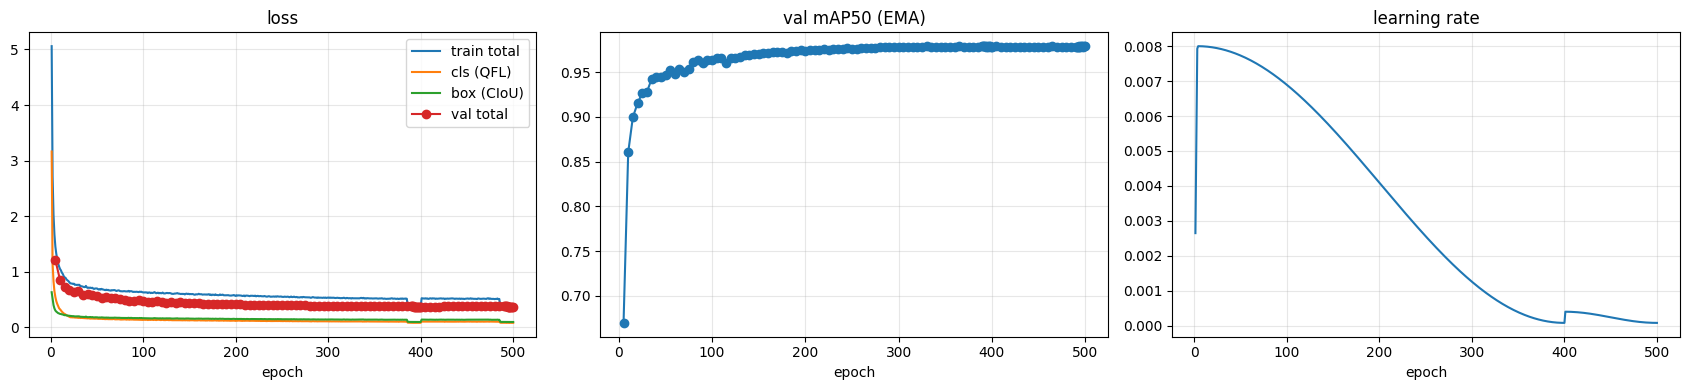


[val] mAP50 = 0.9791  -> uoc tinh diem detection = 68.54/70
[loi @ score>=0.3] {'TP': 7525, 'cls_err': 404, 'loc_err': 348, 'dup': 201, 'bg_fp': 65, 'missed': 254}
  -> sai lop (cls_err) vs sai vi tri (loc_err) cho biet nen sua loss cls hay box; 'missed' = bo sot.
size_px  n_gt  missed  recall
   0-16   301      80   0.734
  16-24  1138      67   0.941
  24-32  1709      45   0.974
  32-48  2660      34   0.987
 48-inf  1971      28   0.986


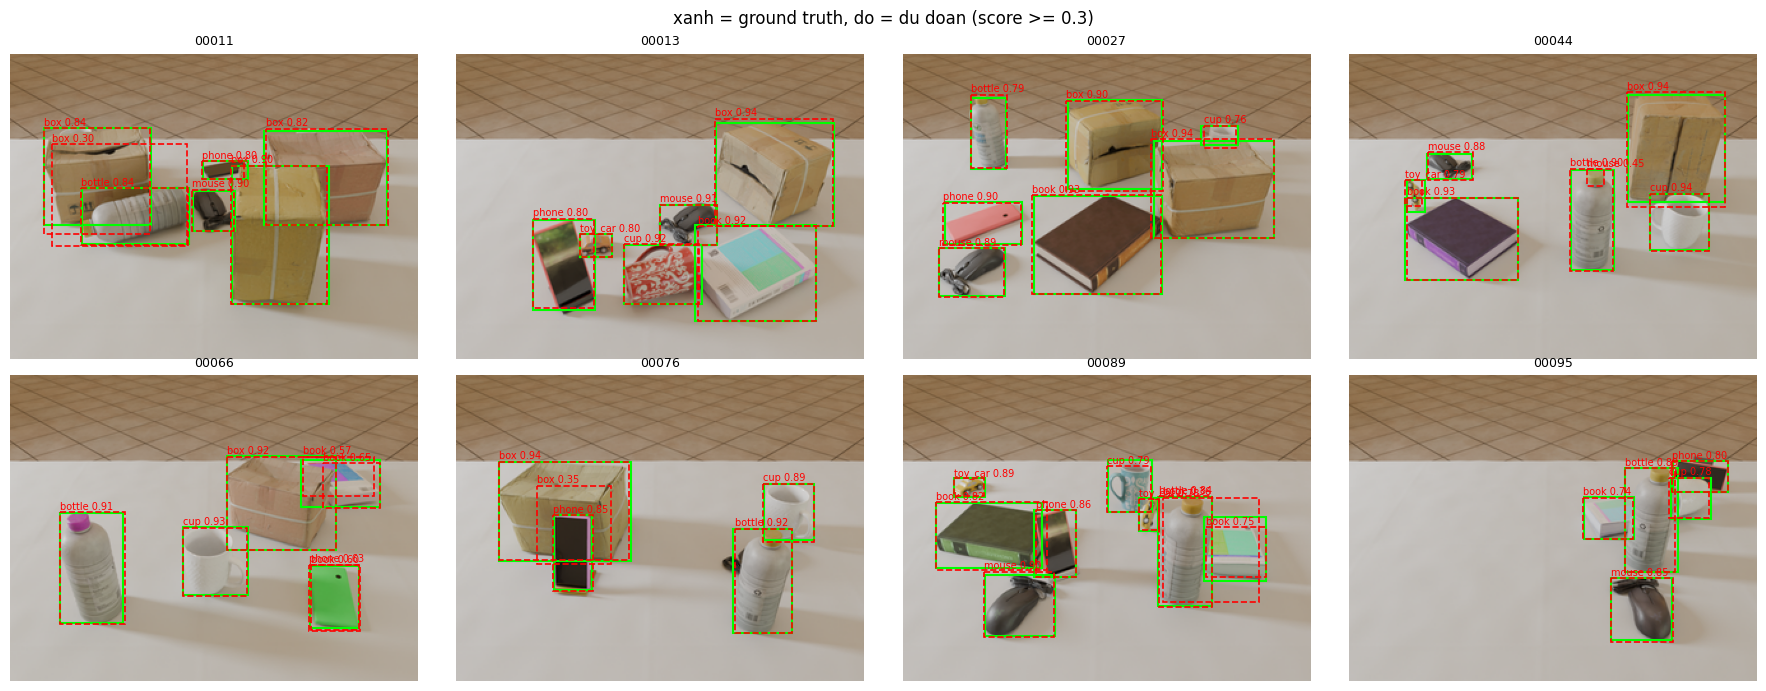

In [9]:
# ============================================================================
# CELL 7 - HIEN THI KET QUA (duong cong train, AP tung lop, loi theo loai, loi theo kich thuoc vat, anh minh hoa)
# ============================================================================
import matplotlib
if os.environ.get("DT_DRYRUN") == "1":
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

assert (DIR_BEST / "best.pt").exists(), "Chua co best/best.pt -> chay cell 6 voi RUN_MODE='train' truoc (bench khong luu gi)."
log = pd.read_csv(DIR_CKPT / "log.csv")
ck_best = torch.load(DIR_BEST / "best.pt", map_location="cpu", weights_only=False)
print(f"[best] epoch {ck_best['epoch']} | mAP50 (val, EMA) = {ck_best['map50']:.4f}")
print(pd.Series(ck_best["per_class_ap"], name="AP50").round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(log["epoch"], log["loss"], label="train total")
ax[0].plot(log["epoch"], log["loss_cls"], label="cls (QFL)")
ax[0].plot(log["epoch"], log["loss_box"], label="box (CIoU)")
ev = log.dropna(subset=["val_loss"])
ax[0].plot(ev["epoch"], ev["val_loss"], "o-", label="val total")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ev["epoch"], ev["map50"], "o-")
ax[1].set_title("val mAP50 (EMA)"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=.3)
ax[2].plot(log["epoch"], log["lr"]); ax[2].set_title("learning rate"); ax[2].set_xlabel("epoch"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(DIR_BEST / "curves.png", dpi=110); plt.show()

# --- chay lai best tren val ---
net_best = DTNet(ck_best["spec"]).to(DEVICE)
net_best.load_state_dict(ck_best["ema"])
dets_val, _ = run_model(net_best, val_loader, DEVICE, CFG.AMP and DEVICE.type == "cuda", CFG)
map50, aps = evaluate_map(dets_val, VAL_GT)
print(f"\n[val] mAP50 = {map50:.4f}  -> uoc tinh diem detection = {70 * map50:.2f}/70")


# error_breakdown() da duoc dinh nghia o CELL 5 (Trainer cung dung de ghi FP vao log.csv)
cnt, miss_sizes = error_breakdown(dets_val, VAL_GT, 0.3)
print("[loi @ score>=0.3]", cnt)
print("  -> sai lop (cls_err) vs sai vi tri (loc_err) cho biet nen sua loss cls hay box; 'missed' = bo sot.")

# recall theo kich thuoc vat the
all_sizes = np.array([math.sqrt(max(0.0, (g[3] - g[1]) * (g[4] - g[2]))) for gt in VAL_GT for g in gt])
miss_sizes = np.array(miss_sizes)
bins = [(0, 16), (16, 24), (24, 32), (32, 48), (48, 1e9)]
rows = []
for lo, hi in bins:
    n = int(((all_sizes >= lo) & (all_sizes < hi)).sum())
    m = int(((miss_sizes >= lo) & (miss_sizes < hi)).sum())
    rows.append(dict(size_px=f"{lo}-{int(hi) if hi < 1e8 else 'inf'}", n_gt=n, missed=m, recall=round(1 - m / n, 3) if n else np.nan))
print(pd.DataFrame(rows).to_string(index=False))

# anh minh hoa
n_show = min(8, len(VAL_IDS))
fig, axs = plt.subplots(2, 4, figsize=(18, 7))
for a, k in zip(axs.ravel(), range(n_show)):
    im = cv2.cvtColor(cv2.imread(str(TRAIN_IMG_DIR / f"{VAL_IDS[k]}.png")), cv2.COLOR_BGR2RGB)
    a.imshow(im); a.axis("off"); a.set_title(VAL_IDS[k], fontsize=9)
    for c, x1, y1, x2, y2 in VAL_GT[k]:
        a.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=1.5))
    for x1, y1, x2, y2, s, c in (dets_val[k][dets_val[k][:, 4] >= 0.3] if len(dets_val[k]) else []):
        a.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=1.2, ls="--"))
        a.text(x1, max(y1 - 2, 0), f"{CLASS_NAMES[int(c)]} {s:.2f}", color="red", fontsize=7)
plt.suptitle("xanh = ground truth, do = du doan (score >= 0.3)"); plt.tight_layout()
plt.savefig(DIR_BEST / "val_preview.png", dpi=110); plt.show()


In [10]:
# ============================================================================
# CELL 8 - DU DOAN + XUAT INT8 + FILE NOP
# ----------------------------------------------------------------------------
# 1) Nap best.pt -> kiem tra mAP50 FP32 tren val.
# 2) Dung ban Keras tuong duong tu CUNG `spec`, chep trong so, KIEM TRA khop PyTorch (sai so < 1e-3).
# 3) Luong tu hoa INT8 day du (PTQ, input/output int8) -> export/dt_detector_int8.tflite ; kiem tra tham so, dung luong, op.
# 4) Do mAP50 cua file INT8 tren val (so voi FP32) va DU DOAN TEST bang file INT8 -> export/submission_detection_int8.csv
#    (de bai: bai nop phai tu mo hinh INT8). Neu khong co TensorFlow -> chi xuat ban FP32, danh dau "NOT_FOR_SUBMIT".
# Quy tac: KHONG tu nop Kaggle. Kiem tra file xong roi ban tu quyet dinh.
# ============================================================================
import csv
import io

SUBMIT_SCORE_THR = 0.001          # nguong score khi xuat CSV (mAP khong bi phat khi ha thap; xem thong ke so box in ra)
ALLOWED_OPS = {"CONV_2D", "DEPTHWISE_CONV_2D", "ADD", "CONCATENATION", "RESHAPE", "RELU", "RELU6", "MAX_POOL_2D",
               "AVERAGE_POOL_2D", "RESIZE_NEAREST_NEIGHBOR", "FULLY_CONNECTED", "SOFTMAX", "LOGISTIC", "MEAN"}
AMP_EVAL = CFG.AMP and DEVICE.type == "cuda"

# ------------------------------ 1) nap best ----------------------------------
assert (DIR_BEST / "best.pt").exists(), "Chua co best/best.pt -> chay cell 6 voi RUN_MODE='train' truoc."
ck = torch.load(DIR_BEST / "best.pt", map_location="cpu", weights_only=False)
m_ = ck["meta"]
for key in ("IMG_W", "IMG_H", "HEAD_CH", "USE_P2", "MAX_DIST", "STRIDE"):
    assert m_[key] == getattr(CFG, key), f"CFG.{key}={getattr(CFG, key)} khac luc train ({m_[key]}). Sua lai CFG cho khop."
net = DTNet(ck["spec"]).to(DEVICE)
net.load_state_dict(ck["ema"])
net.eval()
dets_val_fp32, _ = run_model(net, val_loader, DEVICE, AMP_EVAL, CFG)
map_fp32, _ = evaluate_map(dets_val_fp32, VAL_GT)
print(f"[FP32] best epoch {ck['epoch']} | val mAP50 = {map_fp32:.4f}")


# ------------------------------ ghi file nop ---------------------------------
def dets_to_rows(dets, ids, thr):
    rows = []
    for d, sid in zip(dets, ids):
        d = d[d[:, 4] >= thr] if len(d) else d
        items = [dict(class_id=int(r[5]), score=round(float(r[4]), 5), bbox=[round(float(v), 2) for v in r[:4]]) for r in d]
        rows.append(("DETECTION", sid, json.dumps(items, separators=(",", ":"))))
    return rows


def write_submission(dets, ids, path, thr=SUBMIT_SCORE_THR, intent_csv=CFG.INTENT_PRED_CSV):
    rows = dets_to_rows(dets, ids, thr)
    n_box = [len(json.loads(r[2])) for r in rows]
    if intent_csv:
        it = pd.read_csv(intent_csv)
        assert {"sample_id", "prediction"} <= set(it.columns), "INTENT_PRED_CSV can cot sample_id, prediction"
        rows += [("INTENT", r.sample_id, r.prediction) for r in it.itertuples()]
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["task_type", "sample_id", "prediction"])
        w.writerows(rows)
    # doi chieu sample_submission.csv
    ss = pd.read_csv(DATA_ROOT / "sample_submission.csv")
    ss_det = set(ss.loc[ss.task_type == "DETECTION", "sample_id"])
    mine = {r[1] for r in rows if r[0] == "DETECTION"}
    full = (len(ss_det) == len(mine)) and ss_det == mine
    ok_ids = mine <= ss_det
    print(f"[csv] {path.name}: {len(rows)} dong | DETECTION {len(mine)} | box tong {sum(n_box)} | "
          f"{np.mean(n_box):.1f} box/anh (min {min(n_box)}, max {max(n_box)}) | nguong {thr}")
    print(f"[csv] id DETECTION khop sample_submission: {'DU 4000' if full else ('tap con (dry-run)' if ok_ids else 'SAI ID!')}"
          + ("" if intent_csv else " | chua ghep INTENT (dat CFG.INTENT_PRED_CSV de ghep)"))
    return path


test_ds = ImageOnlyDataset(TEST_IMG_DIR, TEST_IDS, CFG.IMG_W, CFG.IMG_H)
test_loader = make_loader(test_ds, 64, False, min(CFG.NUM_WORKERS, 2))
dets_test_fp32, _ = run_model(net, test_loader, DEVICE, AMP_EVAL, CFG)
write_submission(dets_test_fp32, TEST_IDS, DIR_EXPORT / "FP32_NOT_FOR_SUBMIT_detection.csv")

# ------------------------------ 2) ban Keras tuong duong ---------------------
if not CFG.EXPORT_INT8:
    print("[int8] EXPORT_INT8=False -> bo qua.")
else:
    try:
        os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
        import tensorflow as tf
        try:
            tf.config.set_visible_devices([], "GPU")                # TF chi dung CPU (GPU danh cho PyTorch)
        except Exception:                                           # noqa
            pass
        import keras
        from keras import layers
        HAVE_TF = True
    except Exception as e:                                           # noqa
        HAVE_TF = False
        print(f"[int8] KHONG co TensorFlow ({e}). Cai ban CPU de xuat INT8:  pip install tensorflow")

if CFG.EXPORT_INT8 and HAVE_TF:
    def build_keras_from_spec(spec, h, w):
        inp = keras.Input((h, w, 3), name="image")
        t = {"input": inp}
        for op in spec:
            ty, n = op["t"], op["name"]
            if ty == "conv":
                y = layers.Conv2D(op["cout"], op["k"], strides=op["s"], padding="same", use_bias=op["bias"], name=n)(t[op["src"]])
            elif ty == "dw":
                y = layers.DepthwiseConv2D(op["k"], strides=op["s"], padding="same", use_bias=False, name=n)(t[op["src"]])
            elif ty == "add":
                y = layers.Add(name=n)([t[s] for s in op["srcs"]])
            elif ty == "cat":
                y = layers.Concatenate(axis=-1, name=n)([t[s] for s in op["srcs"]])
            elif ty == "up":
                _, hh, ww, _ = t[op["src"]].shape                     # Resizing(nearest) -> op RESIZE_NEAREST_NEIGHBOR (UpSampling2D sinh TILE/SHAPE... khong hop TFLM)
                y = layers.Resizing(hh * 2, ww * 2, interpolation="nearest", name=n)(t[op["src"]])
            if ty in ("conv", "dw"):
                if op["bn"]:
                    y = layers.BatchNormalization(epsilon=1e-5, momentum=0.9, name=n + "_bn")(y)
                if op["act"]:
                    y = layers.ReLU(6.0, name=n + "_act")(y)
            t[n] = y
        return keras.Model(inp, [t["cls_out"], t["box_out"]], name="DTNet")

    def transfer_weights(net_t, kmodel, spec):
        npy = lambda x: x.detach().cpu().numpy()
        for op in spec:
            if op["t"] not in ("conv", "dw"):
                continue
            m = net_t.mods[op["name"]]
            w = npy(m.weight)
            ws = [w.transpose(2, 3, 1, 0) if op["t"] == "conv" else w.transpose(2, 3, 0, 1)]
            if op["bias"]:
                ws.append(npy(m.bias))
            kmodel.get_layer(op["name"]).set_weights(ws)
            if op["bn"]:
                bn = net_t.mods[op["name"] + "_bn"]
                kmodel.get_layer(op["name"] + "_bn").set_weights(
                    [npy(bn.weight), npy(bn.bias), npy(bn.running_mean), npy(bn.running_var)])

    net_cpu = copy.deepcopy(net).float().cpu().eval()
    kmodel = build_keras_from_spec(ck["spec"], CFG.IMG_H, CFG.IMG_W)
    transfer_weights(net_cpu, kmodel, ck["spec"])
    k_params = kmodel.count_params()
    print(f"[keras] tham so (count_params, gom BN mean/var) = {k_params:,}  | torch strict = {count_params_strict(net_cpu):,}")
    assert k_params <= CFG.PARAM_LIMIT, f"VUOT GIOI HAN {CFG.PARAM_LIMIT:,}"

    # --- kiem tra khop PyTorch <-> Keras tren anh that ---
    x0 = np.stack([ImageOnlyDataset(TRAIN_IMG_DIR, VAL_IDS[:2], CFG.IMG_W, CFG.IMG_H)[k][0].numpy() for k in range(2)]) / 255.0
    with torch.no_grad():
        tc, tb = net_cpu(torch.from_numpy(x0.astype(np.float32)))
    kc, kb = kmodel(x0.transpose(0, 2, 3, 1).astype(np.float32), training=False)
    d_cls = float(np.abs(tc.numpy() - np.asarray(kc).transpose(0, 3, 1, 2)).max())
    d_box = float(np.abs(tb.numpy() - np.asarray(kb).transpose(0, 3, 1, 2)).max())
    print(f"[keras] sai khac toi da PyTorch vs Keras: cls {d_cls:.2e} | box {d_box:.2e}")
    assert d_cls < 1e-2 and d_box < 1e-2, "Ban Keras KHONG khop PyTorch (kiem tra padding/BN)."

    # --- luong tu hoa INT8 day du ---
    calib_ids = TRAIN_IDS[:: max(1, len(TRAIN_IDS) // CFG.CALIB_IMAGES)][: CFG.CALIB_IMAGES]
    calib_ds = ImageOnlyDataset(TRAIN_IMG_DIR, calib_ids, CFG.IMG_W, CFG.IMG_H)

    def representative_dataset():
        for k in range(len(calib_ds)):
            yield [(calib_ds[k][0].numpy().transpose(1, 2, 0)[None].astype(np.float32) / 255.0)]

    conv = tf.lite.TFLiteConverter.from_keras_model(kmodel)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = representative_dataset
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8
    conv.inference_output_type = tf.int8
    tfl = conv.convert()
    path_tfl = DIR_EXPORT / "dt_detector_int8.tflite"
    path_tfl.write_bytes(tfl)
    size_kb = len(tfl) / 1024
    print(f"[int8] da luu {path_tfl.name}: {size_kb:.1f} KB (gioi han 1536 KB)")
    assert size_kb <= 1536, "File INT8 > 1.5 MB"

    # --- kiem tra op / dtype ---
    it = tf.lite.Interpreter(model_content=tfl, num_threads=4)
    it.allocate_tensors()
    inp = it.get_input_details()[0]
    outs = it.get_output_details()
    try:
        ops = sorted({d["op_name"] for d in it._get_ops_details()} - {"DELEGATE"})   # DELEGATE = XNNPACK cua interpreter, khong nam trong file
    except Exception:                                              # noqa
        ops = []
    bad = [o for o in ops if o not in ALLOWED_OPS]
    print(f"[int8] input {inp['dtype'].__name__} {tuple(inp['shape'])} scale/zp {inp['quantization']}")
    for o in outs:
        print(f"[int8] output {o['dtype'].__name__} {tuple(o['shape'])} scale/zp {o['quantization']}")
    print(f"[int8] ops: {ops}")
    print("[int8] " + ("tat ca op nam trong danh sach cho phep" if not bad else f"CHU Y op ngoai danh sach AGENTS.md: {bad} (QUANTIZE/DEQUANTIZE o bien la binh thuong, hay kiem tra voi BTC)"))

    in_scale, in_zp = inp["quantization"]
    o_cls = [o for o in outs if o["shape"][-1] == NUM_CLASSES][0]
    o_box = [o for o in outs if o["shape"][-1] == 4][0]

    def tflite_dets(ids, img_dir):
        sx, sy = ORIG_W / CFG.IMG_W, ORIG_H / CFG.IMG_H
        ds = ImageOnlyDataset(img_dir, ids, CFG.IMG_W, CFG.IMG_H)
        res = []
        for k in range(len(ds)):
            x = ds[k][0].numpy().transpose(1, 2, 0).astype(np.float32) / 255.0
            q = np.clip(np.round(x / in_scale + in_zp), -128, 127).astype(np.int8)[None]
            it.set_tensor(inp["index"], q)
            it.invoke()
            rc, rb = it.get_tensor(o_cls["index"]), it.get_tensor(o_box["index"])
            sc, zc = o_cls["quantization"]; sb, zb = o_box["quantization"]
            cls_l = ((rc.astype(np.float32) - zc) * sc).transpose(0, 3, 1, 2)
            box_r = ((rb.astype(np.float32) - zb) * sb).transpose(0, 3, 1, 2)
            res.append(decode_batch(cls_l, box_r, CFG, None, sx, sy)[0])
        return res

    t0 = time.time()
    dets_val_int8 = tflite_dets(VAL_IDS, TRAIN_IMG_DIR)
    map_int8, aps8 = evaluate_map(dets_val_int8, VAL_GT)
    drop = (map_fp32 - map_int8) * 100
    print(f"[INT8] val mAP50 = {map_int8:.4f} | FP32 {map_fp32:.4f} | chenh {drop:+.2f} diem  ({time.time()-t0:.0f}s)")
    if drop > 2.0:
        print("  ! INT8 giam > 2 diem: kiem tra thang do output (scale/zp), tang CALIB_IMAGES, hoac xem lai kenh depthwise.")

    dets_test_int8 = tflite_dets(TEST_IDS, TEST_IMG_DIR)
    sub_path = write_submission(dets_test_int8, TEST_IDS, DIR_EXPORT / "submission_detection_int8.csv")

    report = dict(best_epoch=ck["epoch"], params_keras=k_params, params_folded=count_params_folded(ck["spec"]),
                  size_kb=round(size_kb, 1), map50_fp32=round(map_fp32, 4), map50_int8=round(map_int8, 4),
                  input_quant=[float(in_scale), int(in_zp)], ops=ops, img=[CFG.IMG_W, CFG.IMG_H],
                  preprocessing="RGB, resize INTER_AREA (neu != 320x240), pixel/255 roi luong tu hoa int8: q=round(x/scale)+zp",
                  decode=dict(stride=CFG.STRIDE, max_dist=CFG.MAX_DIST, nms_iou=CFG.NMS_IOU, max_det=CFG.MAX_DET,
                              output="cls logits -> sigmoid ; box raw -> sigmoid*max_dist*stride = ltrb quanh tam o"),
                  seed=CFG.SEED, fold=CFG.FOLD)
    (DIR_EXPORT / "export_report.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
    print(f"[done] {sub_path}\n       (chua nop gi len Kaggle. Doc export_report.json va kiem tra truoc khi nop.)")


[FP32] best epoch 392 | val mAP50 = 0.9791
[csv] FP32_NOT_FOR_SUBMIT_detection.csv: 4000 dong | DETECTION 4000 | box tong 399996 | 100.0 box/anh (min 96, max 100) | nguong 0.001
[csv] id DETECTION khop sample_submission: DU 4000 | chua ghep INTENT (dat CFG.INTENT_PRED_CSV de ghep)
[keras] tham so (count_params, gom BN mean/var) = 191,579  | torch strict = 191,579
[keras] sai khac toi da PyTorch vs Keras: cls 1.00e-05 | box 9.54e-06
INFO:tensorflow:Assets written to: C:\Users\DuyToan\AppData\Local\Temp\tmphujq6lay\assets


INFO:tensorflow:Assets written to: C:\Users\DuyToan\AppData\Local\Temp\tmphujq6lay\assets


Saved artifact at 'C:\Users\DuyToan\AppData\Local\Temp\tmphujq6lay'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 240, 320, 3), dtype=tf.float32, name='image')
Output Type:
  List[TensorSpec(shape=(None, 30, 40, 7), dtype=tf.float32, name=None), TensorSpec(shape=(None, 30, 40, 4), dtype=tf.float32, name=None)]
Captures:
  2531212098640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531212098256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531214181008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531212099024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531212099216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531212099408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531214181584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531214182544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2531214182160: TensorSpec(shape=(), dtype=tf.resource, name=None)
